# Churn Risk and Retention Targeting for a Music-Streaming Subscription (KKBox)

**Business question.** A subscription company can only contact a limited number of customers. *Which customers are about to churn, and who is worth contacting first?*

**Data.** KKBox churn challenge (Kaggle): ~993K subscribers, 21.5M transactions, member details. "Churn" = no renewal within 30 days after the membership expires.



## 1. Setup

In [1]:
import os, sys, time, math, warnings, subprocess, importlib.util
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

# install only what is missing (Colab already has most of these)
_pkgs = {"duckdb": "duckdb", "statsmodels": "statsmodels", "sklearn": "scikit-learn"}
_missing = [p for m, p in _pkgs.items() if importlib.util.find_spec(m) is None]
if _missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *_missing], check=True)

pd.set_option("display.max_columns", 50); pd.set_option("display.width", 150)
plt.rcParams["figure.figsize"] = (8, 4.5)

# ---------------- settings ----------------
DATA_DIR   = os.environ.get("KKBOX_DATA_DIR", "/content/data")     # folder with the four Kaggle CSVs
WORK_DIR   = os.environ.get("KKBOX_WORK_DIR", ".")                 # sql/, exports and the database file go here
DB_PATH    = os.path.join(WORK_DIR, "kkbox.duckdb")
SQL_DIR    = os.path.join(WORK_DIR, "sql")
EXPORT_DIR = os.path.join(WORK_DIR, "dashboard_exports")
os.makedirs(SQL_DIR, exist_ok=True); os.makedirs(EXPORT_DIR, exist_ok=True)

FEATURE_CUTOFF    = "2017-02-28"   # features use data up to this date only
RESOLUTION_CUTOFF = "2017-03-31"   # last date of data we can use to see who renewed
CHURN_WINDOW_DAYS = 30             # KKBox rule: churn = no renewal within 30 days after expiry
RANDOM_SEED = 42
COHORT_SAMPLE_PCT = int(os.environ.get("COHORT_SAMPLE_PCT", 100))   # lower (e.g. 10) for a quick trial run
np.random.seed(RANDOM_SEED)
print("data:", DATA_DIR, "| cutoff:", FEATURE_CUTOFF)

data: /content/data | cutoff: 2017-02-28


In [2]:
from pathlib import Path
REQUIRED = ["train.csv", "transactions.csv", "transactions_v2.csv", "members_v3.csv"]
def _have_all(): return all((Path(DATA_DIR) / f).exists() for f in REQUIRED)

if not _have_all():
    from getpass import getpass
    import shutil
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "py7zr", "--upgrade", "kaggle"], check=True)
    import py7zr
    os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)
    tok_path = os.path.expanduser("~/.kaggle/access_token")
    with open(tok_path, "w") as f: f.write(getpass("Kaggle API key: "))
    os.chmod(tok_path, 0o600); os.makedirs(DATA_DIR, exist_ok=True)
    for f in REQUIRED:
        subprocess.run(["kaggle", "competitions", "download", "-c", "kkbox-churn-prediction-challenge", "-f", f + ".7z", "-p", DATA_DIR], check=True)
        with py7zr.SevenZipFile(Path(DATA_DIR) / (f + ".7z"), mode="r") as z: z.extractall(path=DATA_DIR)
    for f in REQUIRED:                       # transactions_v2.csv sometimes lands in a sub-folder
        if not (Path(DATA_DIR) / f).exists():
            hits = sorted(Path(DATA_DIR).rglob(f), key=lambda p: len(str(p)))
            if hits: shutil.copy2(hits[0], Path(DATA_DIR) / f)
assert _have_all(), "input files missing"
for f in REQUIRED: print(f"{f:22s}{(Path(DATA_DIR)/f).stat().st_size/2**20:9.1f} MB")

Kaggle API key: ··········
train.csv                  44.5 MB
transactions.csv         1649.2 MB
transactions_v2.csv       110.0 MB
members_v3.csv            408.1 MB


## 2. SQL pipeline (DuckDB)

DuckDB runs inside the notebook and reads the big CSV files directly, so no database server is needed.
```
raw tables → cleaned tables → labels → features → one modelling table
```

In [3]:
import duckdb
con = duckdb.connect(DB_PATH)
con.execute("PRAGMA memory_limit='6GB'")
con.execute(f"PRAGMA temp_directory='{os.path.join(WORK_DIR, 'duck_tmp')}'")

# values that the .sql files use as {{PLACEHOLDERS}}
PARAMS = {"DATA_DIR": DATA_DIR, "FEATURE_CUTOFF": FEATURE_CUTOFF, "RESOLUTION_CUTOFF": RESOLUTION_CUTOFF,
          "CHURN_WINDOW_DAYS": str(CHURN_WINDOW_DAYS),
          "LABEL_RENEWED": "renewed_extend",   # which renewal rule defines the label (explained in Section 3)
          "CANCEL_AWARE": "1"}                 # 1 = respect cancellation rows when finding the expiry date (Section 3)

def run_sql(name, show=False):
    text = open(os.path.join(SQL_DIR, f"{name}.sql")).read()
    for k, v in PARAMS.items(): text = text.replace("{{" + k + "}}", v)
    t0 = time.time(); res = con.execute(text)
    print(f"[{name}] {time.time()-t0:.0f}s"); return res.df() if show else None

**Step 1: load the raw files**

In [4]:
%%writefile sql/01_load.sql
-- 01_load.sql : raw CSVs -> DuckDB tables (dates parsed from YYYYMMDD integers)
CREATE OR REPLACE TABLE raw_train AS
SELECT * FROM read_csv_auto('{{DATA_DIR}}/train.csv');

CREATE OR REPLACE TABLE raw_members AS
SELECT * FROM read_csv('{{DATA_DIR}}/members_v3.csv',
    types = {'registration_init_time': 'DATE'}, dateformat = '%Y%m%d');

CREATE OR REPLACE TABLE raw_txn AS
SELECT * FROM read_csv('{{DATA_DIR}}/transactions.csv',
    types = {'transaction_date': 'DATE', 'membership_expire_date': 'DATE'},
    dateformat = '%Y%m%d');

CREATE OR REPLACE TABLE raw_txn_v2 AS
SELECT * FROM read_csv('{{DATA_DIR}}/transactions_v2.csv',
    types = {'transaction_date': 'DATE', 'membership_expire_date': 'DATE'},
    dateformat = '%Y%m%d');

Writing sql/01_load.sql


In [5]:
run_sql("01_load")
if COHORT_SAMPLE_PCT < 100:   # optional shortcut for a quick trial run
    con.execute(f"CREATE OR REPLACE TABLE raw_train AS SELECT * FROM raw_train USING SAMPLE {COHORT_SAMPLE_PCT} PERCENT (bernoulli, {RANDOM_SEED})")
print(con.sql("SELECT (SELECT COUNT(*) FROM raw_train) AS customers, (SELECT COUNT(*) FROM raw_members) AS members, "
              "(SELECT COUNT(*) FROM raw_txn) AS transactions_to_feb, (SELECT COUNT(*) FROM raw_txn_v2) AS transactions_march").df())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

[01_load] 74s
   customers  members  transactions_to_feb  transactions_march
0     992931  6769473             21547746             1431009


**Step 2: data-quality audit on the full tables**

In [6]:
%%writefile sql/02_quality_checks.sql
-- 02_quality_checks.sql : null audits, outlier ages, invalid expiry-before-transaction dates, orphan keys
SELECT 'transactions rows (v1)' AS check_name, COUNT(*) AS n FROM raw_txn
UNION ALL SELECT 'transactions rows (v2)', COUNT(*) FROM raw_txn_v2
UNION ALL SELECT 'train cohort size', COUNT(*) FROM raw_train
UNION ALL SELECT 'expire date < transaction date',
       COUNT(*) FROM raw_txn WHERE membership_expire_date < transaction_date
UNION ALL SELECT 'expire date before 2000',
       COUNT(*) FROM raw_txn WHERE membership_expire_date < DATE '2000-01-01'
UNION ALL SELECT 'null expire / amount / plan days',
       COUNT(*) FROM raw_txn
       WHERE membership_expire_date IS NULL OR actual_amount_paid IS NULL OR payment_plan_days IS NULL
UNION ALL SELECT 'members: age outside 1-99',
       COUNT(*) FROM raw_members WHERE bd <= 0 OR bd >= 100
UNION ALL SELECT 'members: missing gender',
       COUNT(*) FROM raw_members WHERE gender IS NULL
UNION ALL SELECT 'members: duplicate msno',
       COUNT(*) - COUNT(DISTINCT msno) FROM raw_members
UNION ALL SELECT 'cohort customers with no transactions',
       COUNT(*) FROM raw_train t WHERE NOT EXISTS (SELECT 1 FROM raw_txn x WHERE x.msno = t.msno)
UNION ALL SELECT 'cohort customers missing from members',
       COUNT(*) FROM raw_train t WHERE NOT EXISTS (SELECT 1 FROM raw_members m WHERE m.msno = t.msno);

Writing sql/02_quality_checks.sql


In [7]:
qc = run_sql("02_quality_checks", show=True)
n_txn = int(qc.loc[qc.check_name == "transactions rows (v1)", "n"].iloc[0])
qc["pct_of_table"] = np.where(qc.check_name.isin(["expire date < transaction date", "expire date before 2000"]), (100 * qc.n / n_txn).round(3), np.nan)
display(qc); qc.to_csv(os.path.join(EXPORT_DIR, "data_quality_audit.csv"), index=False)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

[02_quality_checks] 8s


,check_name,n,pct_of_table
0,transactions rows (v1),21547746,NaN
1,transactions rows (v2),1431009,NaN
2,train cohort size,992931,NaN
3,expire date < transaction date,153660,0.713
4,expire date before 2000,1778,0.008
5,null expire / amount / plan days,0,NaN
6,members: age outside 1-99,4546009,NaN
7,members: missing gender,4429505,NaN
8,members: duplicate msno,0,NaN
9,cohort customers with no transactions,0,NaN


**Step 3: clean the data.** Remove impossible rows (expiry date *before* the transaction date), keep only transactions up to the cutoff, and flag customers with an invalid age.

In [8]:
%%writefile sql/03_staging.sql
-- 03_staging.sql
CREATE OR REPLACE TABLE stg_txn AS
SELECT t.*
FROM raw_txn t
JOIN raw_train c USING (msno)
WHERE t.transaction_date <= DATE '{{FEATURE_CUTOFF}}'
  AND t.membership_expire_date IS NOT NULL
  AND t.membership_expire_date >= t.transaction_date;

CREATE OR REPLACE TABLE stg_members AS
SELECT m.msno,
       m.city,
       m.registered_via,
       m.registration_init_time,
       CASE WHEN m.bd BETWEEN 1 AND 99 THEN m.bd END  AS bd,
       (m.bd IS NULL OR m.bd NOT BETWEEN 1 AND 99)    AS age_missing,
       COALESCE(m.gender, 'unknown')                  AS gender
FROM raw_members m
JOIN raw_train c USING (msno)
QUALIFY ROW_NUMBER() OVER (PARTITION BY m.msno ORDER BY m.registration_init_time, m.city, m.registered_via, m.bd) = 1;

Writing sql/03_staging.sql


In [9]:
run_sql("03_staging")
print(con.sql("SELECT (SELECT COUNT(*) FROM stg_txn) AS clean_transactions, (SELECT COUNT(*) FROM stg_members) AS clean_members").df())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

[03_staging] 32s
   clean_transactions  clean_members
0            15817793         877161


**Step 4: build the churn label.**

When several transactions share the same date and expiry date, the "latest" one is chosen by an explicit tie-break (cancellation first, then plan days, amount and payment method). The label and the features use the identical ordering so they always refer to the same row, and the result no longer changes from run to run.


In [10]:
%%writefile sql/04_labels.sql
-- 04_labels.sql  (cancel-aware version)
-- CANCEL_AWARE = 1 : if a customer's most recent transaction is a cancellation, the membership ends at THAT row's expiry date
--                    (a cancel row can move the expiry EARLIER than the max over older rows)
-- CANCEL_AWARE = 0 : original rule (max expiry over all rows) -> reproduces v1 / the reconciliation numbers
CREATE OR REPLACE TABLE last_state AS
WITH ranked AS (
    SELECT msno, membership_expire_date, is_cancel,
           ROW_NUMBER() OVER (PARTITION BY msno ORDER BY transaction_date DESC, membership_expire_date DESC,
                                    is_cancel DESC, payment_plan_days DESC, actual_amount_paid DESC, payment_method_id DESC, is_auto_renew DESC) AS rn,   -- full ordering: same-day ties no longer pick a random row
           MAX(membership_expire_date) OVER (PARTITION BY msno)                                              AS max_expire
    FROM stg_txn
)
SELECT msno,
       CASE WHEN {{CANCEL_AWARE}} = 1 AND is_cancel = 1 THEN membership_expire_date ELSE max_expire END AS last_expire
FROM ranked
WHERE rn = 1;

CREATE OR REPLACE TABLE labels AS
WITH base AS (
    SELECT msno, last_expire, last_expire + {{CHURN_WINDOW_DAYS}} AS window_end
    FROM last_state
    WHERE last_expire + {{CHURN_WINDOW_DAYS}} > DATE '{{FEATURE_CUTOFF}}'
),
renew AS (
    SELECT b.msno,
           MAX(CASE WHEN v.transaction_date >  b.last_expire THEN 1 ELSE 0 END) AS renewed_strict,
           MAX(CASE WHEN v.transaction_date >= b.last_expire THEN 1 ELSE 0 END) AS renewed_sameday,
           MAX(CASE WHEN v.membership_expire_date > b.last_expire THEN 1 ELSE 0 END) AS renewed_extend
    FROM base b
    JOIN raw_txn_v2 v ON v.msno = b.msno
    WHERE v.transaction_date >  DATE '{{FEATURE_CUTOFF}}'
      AND v.transaction_date <= b.window_end
    GROUP BY b.msno
),
flagged AS (
    SELECT b.msno, b.last_expire, b.window_end,
           (b.window_end <= DATE '{{RESOLUTION_CUTOFF}}')  AS resolvable,
           COALESCE(r.renewed_strict, 0)                   AS renewed_strict,
           COALESCE(r.renewed_sameday, 0)                  AS renewed_sameday,
           COALESCE(r.renewed_extend, 0)                   AS renewed_extend
    FROM base b
    LEFT JOIN renew r USING (msno)
)
SELECT msno, last_expire, resolvable, renewed_strict, renewed_sameday, renewed_extend,
       CASE WHEN resolvable AND renewed_strict  = 0 THEN 1 ELSE 0 END AS event_strict,
       CASE WHEN resolvable AND renewed_sameday = 0 THEN 1 ELSE 0 END AS event_sameday,
       CASE WHEN resolvable AND renewed_extend  = 0 THEN 1 ELSE 0 END AS event_extend,
       CASE WHEN resolvable AND {{LABEL_RENEWED}} = 0 THEN 1 ELSE 0 END AS event,
       DATEDIFF('day', DATE '{{FEATURE_CUTOFF}}',
                CASE WHEN resolvable AND {{LABEL_RENEWED}} = 0 THEN window_end
                     ELSE DATE '{{RESOLUTION_CUTOFF}}' END)            AS duration
FROM flagged;

Writing sql/04_labels.sql


In [11]:
run_sql("04_labels")
print(con.sql("SELECT COUNT(*) AS customers, SUM(resolvable::INT) AS outcome_observable, SUM(event) AS churn_events FROM labels").df())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

[04_labels] 34s
   customers  outcome_observable  churn_events
0     987567            121280.0       57981.0


**Step 5: build the features** (all from data up to 28 Feb)

In [12]:
%%writefile sql/05_features.sql
-- 05_features.sql : strictly pre-cutoff (stg_txn only contains transaction_date <= cutoff)
CREATE OR REPLACE TABLE txn_features AS
WITH ranked AS (
    SELECT *,
           ROW_NUMBER() OVER (PARTITION BY msno
                              ORDER BY transaction_date DESC, membership_expire_date DESC,
                                       is_cancel DESC, payment_plan_days DESC, actual_amount_paid DESC, payment_method_id DESC, is_auto_renew DESC) AS rn   -- identical to 04_labels so label and features use the same row
    FROM stg_txn
),
last_txn AS (
    SELECT msno,
           payment_method_id  AS last_payment_method,
           payment_plan_days  AS last_plan_days,
           is_auto_renew      AS last_auto_renew,
           is_cancel          AS last_is_cancel
    FROM ranked
    WHERE rn = 1
),
agg AS (
    SELECT msno,
           COUNT(*)                                            AS n_transactions,
           SUM(is_cancel)                                      AS n_cancels,
           AVG(is_auto_renew)                                  AS auto_renew_ratio,
           AVG(payment_plan_days)                              AS avg_plan_days,
           SUM(actual_amount_paid)                             AS total_amount_paid,
           SUM(payment_plan_days)                              AS total_plan_days,
           COALESCE(AVG(1 - actual_amount_paid / NULLIF(plan_list_price, 0)), 0) AS avg_discount_ratio,
           COUNT(DISTINCT payment_method_id)                   AS n_payment_methods,
           MIN(transaction_date)                               AS first_txn,
           MAX(transaction_date)                               AS last_txn_date,
           SUM(CASE WHEN transaction_date > DATE '{{FEATURE_CUTOFF}}' - 90 THEN 1 ELSE 0 END)         AS n_txn_last_90d,
           SUM(CASE WHEN transaction_date > DATE '{{FEATURE_CUTOFF}}' - 90 THEN is_cancel ELSE 0 END) AS n_cancel_last_90d
    FROM stg_txn
    GROUP BY msno
)
SELECT a.*,
       l.* EXCLUDE (msno),
       a.n_cancels * 1.0 / a.n_transactions                                    AS cancel_rate,
       DATEDIFF('day', a.last_txn_date, DATE '{{FEATURE_CUTOFF}}')             AS days_since_last_txn,
       a.total_amount_paid * 30.0 / GREATEST(a.total_plan_days, 30)            AS spend_per_30d
FROM agg a
JOIN last_txn l USING (msno);

Writing sql/05_features.sql


In [13]:
run_sql("05_features")
print(con.sql("SELECT COUNT(*) AS customers_with_features FROM txn_features").df())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

[05_features] 40s
   customers_with_features
0                   992928


**Step 6: one modelling table**

In [14]:
%%writefile sql/06_model_table.sql
-- 06_model_table.sql
-- `resolvable` and `last_expire` are kept ONLY for diagnostics (censoring-bias check); they are never model inputs.
-- `event_strict/sameday/extend` are kept only for label-quality comparison.
-- `is_churn_official` (Kaggle's label) is an EVALUATION / CALIBRATION target only - never a feature.
CREATE OR REPLACE TABLE model_table AS
SELECT lb.msno, lb.duration, lb.event, lb.event_strict, lb.event_sameday, lb.event_extend, lb.resolvable, lb.last_expire,
       tr.is_churn AS is_churn_official,
       m.city, m.registered_via, m.gender, m.bd,
       COALESCE(m.age_missing, TRUE) AS age_missing,        -- customers absent from members_v3 -> age unknown
       DATEDIFF('day', COALESCE(m.registration_init_time, f.first_txn), DATE '{{FEATURE_CUTOFF}}') AS tenure_days,
       f.* EXCLUDE (msno, first_txn, last_txn_date, total_plan_days)
FROM labels lb
LEFT JOIN raw_train tr USING (msno)
LEFT JOIN stg_members m USING (msno)
LEFT JOIN txn_features f USING (msno);

Writing sql/06_model_table.sql


In [15]:
run_sql("06_model_table")

# ---------- safety checks ----------
latest = con.sql("SELECT MAX(transaction_date) FROM stg_txn").fetchone()[0]
assert str(latest) <= FEATURE_CUTOFF, f"features use data after the cutoff: {latest}"
assert con.sql("SELECT COUNT(*) - COUNT(DISTINCT msno) FROM model_table").fetchone()[0] == 0, "duplicate customers"
assert con.sql("SELECT COUNT(*) FROM model_table WHERE n_transactions IS NULL OR duration IS NULL").fetchone()[0] == 0, "unexpected NULLs"
print(f"OK: latest transaction used for features = {latest} (cutoff {FEATURE_CUTOFF}) | no duplicate customers | no NULLs in core columns")
print(con.sql("SELECT COUNT(*) AS customers FROM model_table").df())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

[06_model_table] 8s
OK: latest transaction used for features = 2017-02-28 (cutoff 2017-02-28) | no duplicate customers | no NULLs in core columns
   customers
0     987567


## 3. Is my churn label correct? (checking it against Kaggle's official flag)


In [16]:
def confusion_metrics(TP, FP, FN, TN):
    n = TP + FP + FN + TN
    prec, rec = TP / max(TP + FP, 1), TP / max(TP + FN, 1)
    po = (TP + TN) / n; pe = ((TP + FP) * (TP + FN) + (FN + TN) * (FP + TN)) / n**2
    return dict(precision=round(prec, 4), recall=round(rec, 4), F1=round(2 * prec * rec / max(prec + rec, 1e-12), 4), kappa=round((po - pe) / (1 - pe), 4))

def cohort_confusion(event_col):
    """Compare a label column with Kaggle's flag on the FULL cohort. Customers missing from model_table
    (already churned before the cutoff) count as predicted churn."""
    t = con.sql(f"""SELECT t.is_churn AS y, COALESCE(m.{event_col}, 1) AS pred, COUNT(*) AS n
                    FROM raw_train t LEFT JOIN model_table m USING (msno) GROUP BY 1, 2""").df()
    f = lambda y, p: int(t[(t.y == y) & (t.pred == p)].n.sum())
    return f(1, 1), f(0, 1), f(1, 0), f(0, 0)

BUCKET_SQL = f"""
SELECT CASE WHEN last_expire <= DATE '2017-03-01' THEN 'a: expires by 1 Mar (at risk)'
            WHEN last_expire <= DATE '2017-03-15' THEN 'b: 2-15 Mar' ELSE 'c: 16-31 Mar' END AS last_expire_bucket,
       last_is_cancel, COUNT(*) AS customers, ROUND(AVG(is_churn_official), 3) AS official_churn_rate
FROM model_table GROUP BY 1, 2 ORDER BY 1, 2"""

rows, buckets = [], {}
n_cohort = con.sql("SELECT COUNT(*) FROM raw_train").fetchone()[0]
for flag, expiry_name in [("0", "max expiry over all rows"), ("1", "cancel-aware (latest transaction)")]:
    PARAMS["CANCEL_AWARE"] = flag
    run_sql("04_labels"); run_sql("06_model_table")
    n_model = con.sql("SELECT COUNT(*) FROM model_table").fetchone()[0]
    for col, rule_name in [("event_strict", "strict (after expiry)"), ("event_sameday", "same-day (on/after expiry)"), ("event_extend", "membership extended")]:
        rows.append({"expiry rule": expiry_name, "renewal rule": rule_name, "customers set aside": n_cohort - n_model,
                     **confusion_metrics(*cohort_confusion(col))})
    buckets[expiry_name] = con.sql(BUCKET_SQL).df()
    if flag == "0":
        chk = con.sql("SELECT COUNT(*) AS rows, SUM(resolvable::INT) AS at_risk, SUM(event_strict) AS strict_events FROM labels").df().iloc[0]
        print("SQL (first rule) gives:", chk.to_dict(), "\nMy original pandas version gave: rows 992,928 | at risk 121,370 | strict events 74,396  (full data only)\n")

label_table = pd.DataFrame(rows); display(label_table)
label_table.to_csv(os.path.join(EXPORT_DIR, "label_quality.csv"), index=False)

PARAMS["CANCEL_AWARE"] = "1"                       # final choice
run_sql("04_labels"); run_sql("06_model_table")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

[04_labels] 30s


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

[06_model_table] 6s
SQL (first rule) gives: {'rows': 992928.0, 'at_risk': 121370.0, 'strict_events': 74396.0} 
My original pandas version gave: rows 992,928 | at risk 121,370 | strict events 74,396  (full data only)



FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

... (4 outputs left out)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

[04_labels] 29s


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

[06_model_table] 8s


In [17]:
for name, tb in buckets.items():
    print(f"--- expiry rule: {name} ---"); display(tb)
print("Customers whose last transaction is a cancel and whose max-expiry falls in March churn at ~80% (Kaggle's flag).")
print("The cancel-aware rule recognises that their membership really ended earlier.")

--- expiry rule: max expiry over all rows ---


,last_expire_bucket,last_is_cancel,customers,official_churn_rate
0,a: expires by 1 Mar (at risk),0,105157,0.308
1,a: expires by 1 Mar (at risk),1,16213,0.927
2,b: 2-15 Mar,0,388802,0.011
3,b: 2-15 Mar,1,5551,0.799
4,c: 16-31 Mar,0,474253,0.011
5,c: 16-31 Mar,1,2952,0.769


--- expiry rule: cancel-aware (latest transaction) ---


,last_expire_bucket,last_is_cancel,customers,official_churn_rate
0,a: expires by 1 Mar (at risk),0,105157,0.308
1,a: expires by 1 Mar (at risk),1,16123,0.911
2,b: 2-15 Mar,0,388802,0.011
3,b: 2-15 Mar,1,1923,0.512
4,c: 16-31 Mar,0,474253,0.011
5,c: 16-31 Mar,1,1309,0.575


Customers whose last transaction is a cancel and whose max-expiry falls in March churn at ~80% (Kaggle's flag).
The cancel-aware rule recognises that their membership really ended earlier.


In [18]:
first = label_table[(label_table["expiry rule"].str.startswith("max")) & (label_table["renewal rule"].str.startswith("strict"))].iloc[0]
chosen = label_table[(label_table["expiry rule"].str.startswith("cancel")) & (label_table["renewal rule"].str.startswith("membership"))].iloc[0]
top = label_table.sort_values("kappa", ascending=False).iloc[0]
print(f"Original rule : recall {first.recall}, precision {first.precision}, kappa {first.kappa}")
print(f"Chosen rule   : recall {chosen.recall}, precision {chosen.precision}, kappa {chosen.kappa}  (cancel-aware expiry + membership-extended renewal)")
print(f"Highest kappa in the table: {top['expiry rule']} + {top['renewal rule']} (kappa {top.kappa}). If a different rule scores clearly higher on your data (more than a few thousandths), look into why before continuing.")
print(f"Customers set aside (already churned before the cut-off, or no history): {int(chosen['customers set aside']):,}")

Original rule : recall 0.7397, precision 0.6311, kappa 0.6574
Chosen rule   : recall 0.8206, precision 0.8222, kappa 0.8092  (cancel-aware expiry + membership-extended renewal)
Highest kappa in the table: cancel-aware (latest transaction) + membership extended (kappa 0.8092). If a different rule scores clearly higher on your data (more than a few thousandths), look into why before continuing.
Customers set aside (already churned before the cut-off, or no history): 5,364


## 4. Who is actually at risk?


In [19]:
# ORDER BY makes the row order (and therefore the random train/test split) identical on every run
raw = con.sql("SELECT * FROM model_table ORDER BY msno").df()
raw["in_pool"] = raw["resolvable"].astype(bool)

facts = raw.groupby("in_pool").agg(customers=("msno", "size"), official_churners=("is_churn_official", "sum"),
                                   official_churn_rate=("is_churn_official", "mean"))
facts.index = facts.index.map({True: "at-risk pool", False: "everyone else"}); facts["share_of_customers"] = facts.customers / facts.customers.sum()
display(facts.round(4))
cover = facts.loc["at-risk pool", "official_churners"] / facts.official_churners.sum()
print(f"The pool is {facts.loc['at-risk pool','share_of_customers']:.1%} of customers but contains {cover:.1%} of all remaining churners.")
print(f"Overall churn rate is only {raw.is_churn_official.mean():.1%}, so 'accuracy' would be ~{1 - raw.is_churn_official.mean():.0%} even for a model that predicts nobody churns.")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,customers,official_churners,official_churn_rate,share_of_customers
in_pool,,,,
everyone else,866287,11114,0.0128,0.8772
at-risk pool,121280,47039,0.3879,0.1228


The pool is 12.3% of customers but contains 80.9% of all remaining churners.
Overall churn rate is only 5.9%, so 'accuracy' would be ~94% even for a model that predicts nobody churns.


In [20]:
cols = ["days_since_last_txn", "auto_renew_ratio", "last_auto_renew", "n_txn_last_90d", "n_transactions", "last_is_cancel", "last_plan_days", "tenure_days"]
a, b = raw[raw.in_pool], raw[~raw.in_pool]
smd = pd.DataFrame({"mean_pool": [a[c].astype(float).mean() for c in cols], "mean_rest": [b[c].astype(float).mean() for c in cols]}, index=cols)
smd["SMD"] = [(a[c].astype(float).mean() - b[c].astype(float).mean()) / math.sqrt((a[c].astype(float).var() + b[c].astype(float).var()) / 2) for c in cols]
display(smd.round(3))
print("The pool = lapsed customers (long since last transaction, auto-renew off, recent cancellations).")

,mean_pool,mean_rest,SMD
days_since_last_txn,70.316,14.327,0.776
auto_renew_ratio,0.595,0.915,-0.839
last_auto_renew,0.587,0.930,-0.876
n_txn_last_90d,1.917,2.875,-1.090
n_transactions,11.571,16.531,-0.604
last_is_cancel,0.133,0.004,0.530
last_plan_days,64.668,29.986,0.522
tenure_days,1109.407,1185.650,-0.073


The pool = lapsed customers (long since last transaction, auto-renew off, recent cancellations).


## 5. Preparing the at-risk pool for modelling

* **Target:** Kaggle's official churn flag (`is_churn_official`), the cleanest outcome available.
* **Missing members:** customers with no member record get `age_missing = 1`, gender "unknown", city "missing".
* **Rare categories** (under 1%) are pooled into "other".
* Skewed counts and amounts use `log1p`, then every numeric feature is standardized with **training-set** mean and SD, so a coefficient means "per +1 SD".
* **Split:** 75% train / 25% test, stratified on churn. The test set is used only for final reporting.

In [21]:
from sklearn.model_selection import train_test_split

P = raw[raw["in_pool"]].reset_index(drop=True).copy()

# DuckDB can return pandas "nullable" types; convert numeric ones to plain floats
for c in P.columns:
    if c in ("msno", "city", "registered_via", "last_payment_method"): continue
    if pd.api.types.is_extension_array_dtype(P[c].dtype) and (pd.api.types.is_numeric_dtype(P[c].dtype) or pd.api.types.is_bool_dtype(P[c].dtype)):
        P[c] = P[c].astype("float64")

n_no_member = int(P["city"].isna().sum())
P["age_missing"] = P["age_missing"].fillna(1).astype(int)
P["gender"] = P["gender"].fillna("unknown")
print(f"At-risk pool: {len(P):,} customers | {n_no_member:,} have no member record")

def _as_cat(v):
    if v is None or v is pd.NA or (isinstance(v, (float, np.floating)) and math.isnan(v)): return "missing"
    if isinstance(v, (float, np.floating)) and float(v).is_integer(): return str(int(v))
    return str(v)
def pool_rare(s, min_frac=0.01):
    s = s.astype("object").map(_as_cat); keep = s.value_counts(normalize=True)
    return s.where(s.isin(set(keep[keep >= min_frac].index)), "other")
for c in ["city", "registered_via", "last_payment_method"]: P[c] = pool_rare(P[c])

# group columns for segment summaries (built from the raw values, before any scaling)
P["spend_raw"] = P["spend_per_30d"].astype(float)
P["auto_renew_group"] = pd.cut(P.auto_renew_ratio, [-0.01, 0.33, 0.66, 1.0], labels=["low auto-renew", "medium auto-renew", "high auto-renew"]).astype(str)
P["plan_group"] = pd.cut(P.last_plan_days, [-1, 7, 30, 90, 10**6], labels=["<=7d plan", "8-30d plan", "31-90d plan", ">90d plan"]).astype(str)
P["payment_group"] = "pm_" + P.last_payment_method.where(P.last_payment_method.isin(P.last_payment_method.value_counts().index[:5]), "other")
P["tenure_group"] = pd.cut(P.tenure_days.clip(lower=0), [-1, 180, 365, 730, 10**7], labels=["<6 months", "6-12 months", "1-2 years", ">2 years"]).astype(str)
P["cancel_history"] = np.where(P.n_cancels > 0, "has cancelled before", "never cancelled")
P["tenure_raw"] = P["tenure_days"].clip(lower=0)   # tenure in days, kept for descriptive tests (tenure_days is log-transformed and standardised below)

NUMERIC = ["bd", "tenure_days", "n_transactions", "n_cancels", "auto_renew_ratio", "avg_plan_days", "total_amount_paid", "avg_discount_ratio",
           "cancel_rate", "n_payment_methods", "n_txn_last_90d", "n_cancel_last_90d", "days_since_last_txn", "last_plan_days", "spend_per_30d"]
FLAGS = ["age_missing", "last_auto_renew", "last_is_cancel"]
LOG_COLS = ["tenure_days", "n_transactions", "n_cancels", "total_amount_paid", "avg_plan_days", "last_plan_days", "n_txn_last_90d",
            "n_cancel_last_90d", "days_since_last_txn", "spend_per_30d", "n_payment_methods"]
P["tenure_days"] = P.tenure_days.clip(lower=0); P["days_since_last_txn"] = P.days_since_last_txn.clip(lower=0)
for c in LOG_COLS: P[c] = np.log1p(P[c].astype(float))

dummies = pd.get_dummies(P[["city", "gender", "registered_via", "last_payment_method"]], drop_first=True, dtype=float)
# Customers with no member record are "missing" in BOTH city and registered_via, so those two dummies are identical.
# Keep one copy; otherwise the same signal is counted twice and the design matrix is exactly collinear.
dup_dummies = dummies.columns[dummies.T.duplicated()].tolist()
dummies = dummies.drop(columns=dup_dummies)
print("Dropped duplicate indicator columns:", dup_dummies)
P = pd.concat([P, dummies], axis=1)

idx_train, idx_test = train_test_split(np.arange(len(P)), test_size=0.25, random_state=RANDOM_SEED, stratify=P["is_churn_official"])
P["bd"] = P["bd"].fillna(P.loc[idx_train, "bd"].median())              # train-only median
mu, sd = P.loc[idx_train, NUMERIC].mean(), P.loc[idx_train, NUMERIC].std().replace(0, 1)
P[NUMERIC] = ((P[NUMERIC] - mu) / sd).clip(-6, 6)

const = [c for c in NUMERIC + FLAGS + list(dummies.columns) if P.loc[idx_train, c].std() == 0]
ALL_FEATURES = [c for c in NUMERIC + FLAGS + list(dummies.columns) if c not in const]
assert P[ALL_FEATURES].isna().sum().sum() == 0
print(f"train {len(idx_train):,} | test {len(idx_test):,} | features {len(ALL_FEATURES)} | churn rate train {P.loc[idx_train,'is_churn_official'].mean():.3f}, test {P.loc[idx_test,'is_churn_official'].mean():.3f}")

At-risk pool: 121,280 customers | 11,283 have no member record
Dropped duplicate indicator columns: ['registered_via_missing']
train 90,960 | test 30,320 | features 47 | churn rate train 0.388, test 0.388


## 6. What drives churn? Logistic regression and odds ratios

**Logistic regression** models the log-odds of churn. The **odds ratio** (OR) of a feature is how much the *odds* of churn are multiplied when the feature goes up by 1 SD (numeric features are log-transformed where skewed, then standardised; for 0/1 flags: from 0 to 1). OR above 1 = more churn, below 1 = less. These are **associations, not causes**.

First, **multicollinearity**: if two features carry almost the same information, their coefficients become unstable. The variance inflation factor (VIF) measures this; above 10 is a warning, so I drop the worst feature and repeat.

In [22]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools import add_constant

def vif_table(df, cols):
    X = add_constant(df[cols].astype(float), has_constant="add")
    with warnings.catch_warnings():
        warnings.simplefilter("ignore"); v = [variance_inflation_factor(X.values, i + 1) for i in range(len(cols))]
    return pd.Series(np.minimum(v, 1e6), index=cols).sort_values(ascending=False)

num_now = [c for c in NUMERIC if c in ALL_FEATURES]
vs = P.loc[idx_train, num_now].sample(min(100_000, len(idx_train)), random_state=RANDOM_SEED)
display(vif_table(vs, num_now).round(2).head(6).to_frame("VIF (before)"))
dropped = []
while True:
    v = vif_table(vs, num_now)
    if v.iloc[0] <= 10: break
    dropped.append((v.index[0], round(float(v.iloc[0]), 1))); num_now.remove(v.index[0])
print("Dropped for VIF > 10:", dropped, "| largest VIF now:", round(vif_table(vs, num_now).iloc[0], 2))
FEATURES = num_now + [c for c in ALL_FEATURES if c not in NUMERIC]

,VIF (before)
total_amount_paid,45.40
n_transactions,35.47
avg_plan_days,18.14
spend_per_30d,13.32
n_txn_last_90d,5.96
last_plan_days,5.54


Dropped for VIF > 10: [('total_amount_paid', 45.4)] | largest VIF now: 5.96


In [23]:

import statsmodels.api as sm
import numpy as np
import pandas as pd

# Split using your existing train/test indices
X_train = P.loc[idx_train, FEATURES].astype(float).copy()
X_test  = P.loc[idx_test, FEATURES].astype(float).copy()

ytr = P.loc[idx_train, "is_churn_official"].astype(int)
yte = P.loc[idx_test, "is_churn_official"].astype(int).values

# Replace infinities and impute missing values using training data only
X_train = X_train.replace([np.inf, -np.inf], np.nan)
X_test  = X_test.replace([np.inf, -np.inf], np.nan)

medians = X_train.median()
X_train = X_train.fillna(medians).fillna(0)
X_test  = X_test.fillna(medians).fillna(0)

# Remove constant columns
constant_cols = X_train.columns[X_train.nunique(dropna=False) <= 1].tolist()
X_train = X_train.drop(columns=constant_cols)
X_test  = X_test.drop(columns=constant_cols, errors="ignore")

# Remove exact duplicate columns (none expected: duplicate indicators are already dropped in Section 5)
duplicate_cols = X_train.columns[X_train.T.duplicated()].tolist()
X_train = X_train.drop(columns=duplicate_cols)
X_test  = X_test.drop(columns=duplicate_cols, errors="ignore")

print("Removed constant columns:", constant_cols)
print("Removed duplicate columns:", duplicate_cols)

# Add intercept
Xtr = sm.add_constant(X_train, has_constant="add")
Xte = sm.add_constant(X_test, has_constant="add")
Xte = Xte.reindex(columns=Xtr.columns, fill_value=0)

# Unpenalised maximum-likelihood fit (L-BFGS optimiser). Standard errors and Wald CIs come from the inverse Hessian,
# so they are only trustworthy if the fit converged and the design matrix is not collinear (checked below).
logit = sm.Logit(ytr, Xtr).fit(
    method="lbfgs",
    disp=0,
    maxiter=500
)

print("Converged:", logit.mle_retvals.get("converged"))
print(logit.summary())

# Odds ratios and confidence intervals
ci = logit.conf_int()
odds = pd.DataFrame({
    "feature": logit.params.index,
    "odds_ratio": np.exp(np.clip(logit.params.values, -30, 30)),
    "ci_low": np.exp(np.clip(ci[0].values, -30, 30)),
    "ci_high": np.exp(np.clip(ci[1].values, -30, 30)),
    "p_value": logit.pvalues.values
})

odds = odds[odds.feature != "const"].copy()
odds["effect"] = np.where(
    odds.odds_ratio > 1, "higher churn odds", "lower churn odds"
)
odds = odds.sort_values("odds_ratio", ascending=False)

display(odds.head(15).round(4))
odds.to_csv(os.path.join(EXPORT_DIR, "odds_ratios.csv"), index=False)

p_logit_te = logit.predict(Xte).values


Removed constant columns: []
Removed duplicate columns: []
Converged: True
                           Logit Regression Results                           
Dep. Variable:      is_churn_official   No. Observations:                90960
Model:                          Logit   Df Residuals:                    90913
Method:                           MLE   Df Model:                           46
Date:                Sat, 07 Nov 2026   Pseudo R-squ.:                  0.4313
Time:                        09:40:36   Log-Likelihood:                -34546.
converged:                       True   LL-Null:                       -60741.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------
const                         1.6736      0.117     14.360      0.000       1.445       1.902
bd         

,feature,odds_ratio,ci_low,ci_high,p_value,effect
17,last_is_cancel,356.7593,294.4678,432.2280,0.0000,higher churn odds
29,city_missing,3.8336,3.3074,4.4435,0.0000,higher churn odds
12,days_since_last_txn,1.9283,1.8382,2.0229,0.0000,higher churn odds
11,n_cancel_last_90d,1.5414,1.4498,1.6387,0.0000,higher churn odds
34,registered_via_7,1.3885,1.2394,1.5555,0.0000,higher churn odds
15,age_missing,1.1191,1.0184,1.2297,0.0193,higher churn odds
5,auto_renew_ratio,1.1017,1.0342,1.1737,0.0027,higher churn odds
1,bd,1.0852,1.0650,1.1057,0.0000,higher churn odds
31,gender_male,1.0667,1.0183,1.1174,0.0064,higher churn odds
2,tenure_days,1.0463,1.0177,1.0757,0.0014,higher churn odds


## 7. How good are the predictions? (and is a fancier model worth it?)

On the **held-out test set** (at-risk pool only) compare four scorers:

1. **Rule:** "last transaction was a cancel" (no model at all)
2. **Auto-renew ratio alone**
3. **Logistic regression** (my main model: interpretable, and its probabilities are used in Section 8)
4. **Gradient boosting** (a tree model, to check whether non-linear patterns matter)

Metrics: **AUC** (probability that a random churner is ranked above a random non-churner; 0.5 = coin flip), **precision/recall/lift in the top 10%** of customers by predicted risk (lift = precision divided by the base churn rate).

*Note:* the rule is a 0/1 flag, so more customers tie at the top than fit in 10%, and its precision@top-10% depends on how ties are broken (here: row order). Judge the rule by its AUC and by the policy table in Section 8, which contacts every flagged customer.


,model,AUC,PR-AUC,precision@top10%,recall@top10%,lift@top10%
0,Rule: last transaction was a cancel,0.6449,0.5490,0.9086,0.2343,2.3427
1,Auto-renew ratio only,0.6752,0.5195,0.5834,0.1504,1.5043
2,Logistic regression (main),0.8993,0.8189,0.9172,0.2365,2.3648
3,Gradient boosting (check),0.9255,0.8784,0.9809,0.2529,2.5289


Base churn rate in the at-risk pool (test): 38.8%


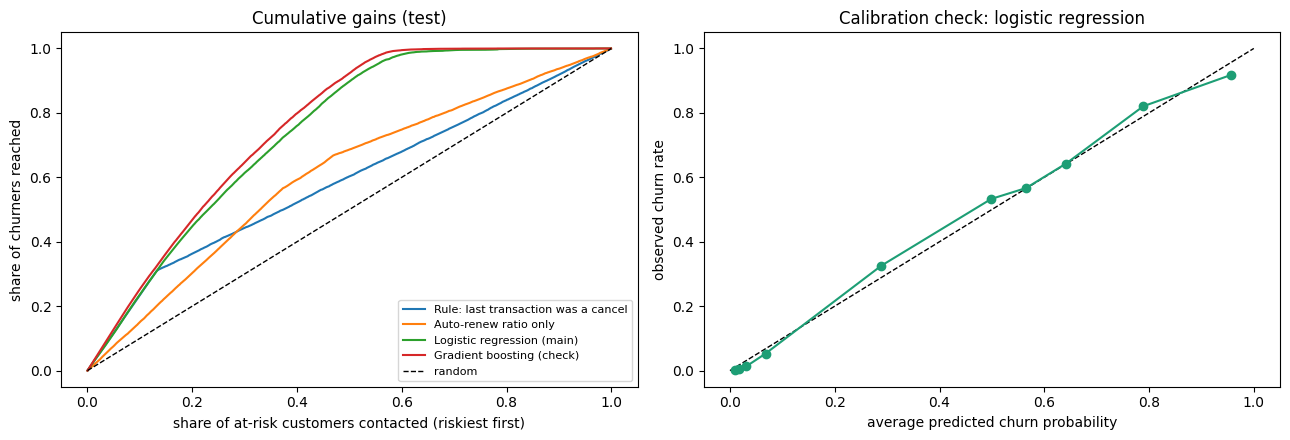

,decile,predicted,observed
0,0,0.010,0.002
1,1,0.018,0.005
2,2,0.031,0.013
3,3,0.068,0.053
4,4,0.289,0.326
5,5,0.499,0.533
6,6,0.565,0.567
7,7,0.642,0.643
8,8,0.789,0.821
9,9,0.956,0.917


In [24]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

gbm = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.1, early_stopping=True, random_state=RANDOM_SEED)
gbm.fit(P.loc[idx_train, ALL_FEATURES].values, ytr.values)
p_gbm_te = gbm.predict_proba(P.loc[idx_test, ALL_FEATURES].values)[:, 1]

te = P.loc[idx_test].reset_index(drop=True)
scores = {"Rule: last transaction was a cancel": te["last_is_cancel"].values.astype(float),
          "Auto-renew ratio only": -te["auto_renew_ratio"].values,
          "Logistic regression (main)": p_logit_te,
          "Gradient boosting (check)": p_gbm_te}

def top_k(score, q):
    k = int(math.ceil(q * len(score))); m = np.zeros(len(score), bool); m[np.argsort(-score, kind="stable")[:k]] = True; return m

base = yte.mean(); rows = []
for name, s in scores.items():
    m = top_k(s, 0.10)
    rows.append({"model": name, "AUC": roc_auc_score(yte, s), "PR-AUC": average_precision_score(yte, s),
                 "precision@top10%": yte[m].mean(), "recall@top10%": yte[m].sum() / yte.sum(), "lift@top10%": yte[m].mean() / base})
perf = pd.DataFrame(rows); display(perf.round(4)); perf.to_csv(os.path.join(EXPORT_DIR, "model_comparison.csv"), index=False)
print(f"Base churn rate in the at-risk pool (test): {base:.1%}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, s in scores.items():
    o = np.argsort(-s, kind="stable"); cum = np.cumsum(yte[o]) / yte.sum(); xs = np.arange(1, len(o) + 1) / len(o)
    axes[0].plot(xs[::20], cum[::20], label=name)
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="random"); axes[0].set_xlabel("share of at-risk customers contacted (riskiest first)")
axes[0].set_ylabel("share of churners reached"); axes[0].set_title("Cumulative gains (test)"); axes[0].legend(fontsize=8)
q = pd.qcut(pd.Series(p_logit_te).rank(method="first"), 10, labels=False)
cal = pd.DataFrame({"decile": q, "pred": p_logit_te, "obs": yte}).groupby("decile").agg(predicted=("pred", "mean"), observed=("obs", "mean")).reset_index()
axes[1].plot([0, 1], [0, 1], "k--", lw=1); axes[1].plot(cal.predicted, cal.observed, "o-", color="#1D9E75")
axes[1].set_xlabel("average predicted churn probability"); axes[1].set_ylabel("observed churn rate"); axes[1].set_title("Calibration check: logistic regression")
plt.tight_layout(); plt.show(); display(cal.round(3)); cal.to_csv(os.path.join(EXPORT_DIR, "calibration_by_decile.csv"), index=False)

## 7A. Leakage and target-proximity sensitivity analysis

**Why this check matters.** All candidate features are timestamped on or before the 28 February 2017 cutoff, so this is not automatically proof of future-data leakage. However, the churn label is constructed using renewal behaviour after expiry and a cancellation-aware expiry rule. `last_is_cancel` directly participates in determining the effective expiry date; recency, cancellation-frequency and auto-renewal variables may also be close proxies for the target. In the logistic regression of Section 6 the odds ratio for `last_is_cancel` is by far the largest of any feature (in the hundreds), which warrants a controlled sensitivity analysis.

The following compares three feature specifications on the **same train/test customers**: (1) the original feature set, (2) excluding the direct cancellation flag, and (3) a conservative set excluding cancellation, recency, auto-renewal and plan-duration signals. The conservative set is a stress test, not necessarily the final production feature set. Interpret it as evidence about how much performance depends on target-proximal signals.

In [25]:
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score
import math
import pandas as pd
import numpy as np

# All specifications use the exact same train/test split and target.
# `FEATURES` is the VIF-screened set used by the original logistic regression;
# `ALL_FEATURES` is the original set used by gradient boosting.
# NOTE: the logistic rows below are an L2-regularised scikit-learn refit (C = 1), so their "Original" row differs
# slightly from the unpenalised statsmodels model of Section 6. All three specifications use the same estimator.
DIRECT_PROXY = {"last_is_cancel"}
TARGET_PROXIMITY_FAMILY = {
    "last_is_cancel", "days_since_last_txn", "n_cancel_last_90d",
    "cancel_rate", "n_cancels", "auto_renew_ratio", "last_auto_renew",
    "n_txn_last_90d", "last_plan_days", "avg_plan_days"
}

def _feature_specs(base_cols):
    base_cols = list(base_cols)
    return {
        "Original": base_cols,
        "Drop last_is_cancel": [c for c in base_cols if c not in DIRECT_PROXY],
        "Conservative (drop cancellation/recency/renewal/plan signals)": [
            c for c in base_cols if c not in TARGET_PROXIMITY_FAMILY
        ],
    }

def _evaluate_scores(y_true, scores):
    k = max(1, int(math.ceil(0.10 * len(y_true))))
    top_idx = np.argsort(-np.asarray(scores), kind="stable")[:k]
    top_y = np.asarray(y_true)[top_idx]
    prevalence = np.mean(y_true)
    return {
        "ROC_AUC": roc_auc_score(y_true, scores),
        "PR_AUC": average_precision_score(y_true, scores),
        "precision_at_10pct": top_y.mean(),
        "recall_at_10pct": top_y.sum() / max(np.sum(y_true), 1),
        "lift_at_10pct": top_y.mean() / prevalence,
        "n_features": None,
    }

sensitivity_rows = []
model_specs = [
    ("Logistic regression (L2, C=1)", FEATURES, LogisticRegression(penalty="l2", C=1.0, max_iter=1500, solver="lbfgs")),
    ("HistGradientBoosting", ALL_FEATURES, HistGradientBoostingClassifier(
        max_iter=300, learning_rate=0.1, early_stopping=True, random_state=RANDOM_SEED
    )),
]

for model_name, base_cols, estimator in model_specs:
    for spec_name, cols in _feature_specs(base_cols).items():
        if len(cols) == 0:
            print(f"Skipping {model_name} / {spec_name}: no features remain")
            continue
        Xtr_s = P.loc[idx_train, cols].astype(float).replace([np.inf, -np.inf], np.nan)
        Xte_s = P.loc[idx_test, cols].astype(float).replace([np.inf, -np.inf], np.nan)
        med = Xtr_s.median().fillna(0)
        Xtr_s = Xtr_s.fillna(med).fillna(0)
        Xte_s = Xte_s.fillna(med).fillna(0)

        fitted = clone(estimator)
        fitted.fit(Xtr_s, ytr.values)
        prob = fitted.predict_proba(Xte_s)[:, 1]
        metrics = _evaluate_scores(yte, prob)
        metrics.update({"model": model_name, "feature_specification": spec_name,
                        "n_features": len(cols)})
        sensitivity_rows.append(metrics)

sensitivity = pd.DataFrame(sensitivity_rows)[
    ["model", "feature_specification", "n_features", "ROC_AUC", "PR_AUC",
     "precision_at_10pct", "recall_at_10pct", "lift_at_10pct"]
]
display(sensitivity.round(4))
sensitivity.to_csv(os.path.join(EXPORT_DIR, "feature_sensitivity.csv"), index=False)

print("Interpretation: compare each model only within its own rows. A large decline after removing target-proximal features indicates that the original score depended heavily on those signals.")
print("Do not call the remaining score leakage-free without validating the feature timestamps and label-generation logic.")


,model,feature_specification,n_features,ROC_AUC,PR_AUC,precision_at_10pct,recall_at_10pct,lift_at_10pct
0,"Logistic regression (L2, C=1)",Original,46,0.8993,0.8192,0.9172,0.2365,2.3648
1,"Logistic regression (L2, C=1)",Drop last_is_cancel,45,0.8814,0.7741,0.8453,0.2179,2.1794
2,"Logistic regression (L2, C=1)",Conservative (drop cancellation/recency/renewa...,36,0.7206,0.6124,0.6962,0.1795,1.7951
3,HistGradientBoosting,Original,47,0.9255,0.8784,0.9809,0.2529,2.5289
4,HistGradientBoosting,Drop last_is_cancel,46,0.9234,0.8743,0.9766,0.2518,2.5179
5,HistGradientBoosting,Conservative (drop cancellation/recency/renewa...,37,0.8451,0.7686,0.9017,0.2325,2.3248


Interpretation: compare each model only within its own rows. A large decline after removing target-proximal features indicates that the original score depended heavily on those signals.
Do not call the remaining score leakage-free without validating the feature timestamps and label-generation logic.


## 7B. Bootstrap confidence intervals for model performance

**Objective.** Quantify sampling uncertainty around held-out ROC-AUC, PR-AUC and precision among the top 10% highest-risk customers.

**Method.** Use a customer-level non-parametric bootstrap in which each customer's label and score stay paired (the two models are resampled separately here; Section 7C compares them on identical resamples). Each resample draws test-customer row indices with replacement; the observed churn label and the corresponding model score are always sampled together. The models are not refitted. The 2.5th and 97.5th percentiles of the bootstrap metric distribution form the percentile 95% confidence interval.

This is an uncertainty interval for performance on a population represented by the held-out test sample. It does not account for model-training variability, feature-selection variability, or temporal/data-distribution shift. The bootstrap is run separately for the original Logistic Regression and HistGradientBoosting test predictions.


In [26]:
# ============================================================
# SECTION 7B: BOOTSTRAP CONFIDENCE INTERVALS
# ============================================================

from sklearn.metrics import roc_auc_score, average_precision_score
import numpy as np
import pandas as pd
import os
import math

# Use the existing held-out labels and predictions.
# Each customer's label and prediction remain paired during resampling.
y_boot = np.asarray(yte).astype(int)

model_scores = {
    "Logistic Regression": np.asarray(p_logit_te, dtype=float),
    "HistGradientBoosting": np.asarray(p_gbm_te, dtype=float)
}

# Reproducibility settings
BOOTSTRAP_REPS = 2000
BOOTSTRAP_SEED = 2026
CONFIDENCE_LEVEL = 0.95
rng = np.random.default_rng(BOOTSTRAP_SEED)

# Basic integrity checks
assert len(y_boot) > 0, "The held-out test set is empty."
assert set(np.unique(y_boot)).issubset({0, 1}), "Target must be binary."
assert len(np.unique(y_boot)) == 2, "Both churn classes must be present."

for model_name, score in model_scores.items():
    assert len(score) == len(y_boot), f"Length mismatch for {model_name}."
    assert np.isfinite(score).all(), f"Non-finite predictions in {model_name}."

def precision_at_10pct(y_true, scores):
    """Precision among exactly the highest-scoring 10% of observations."""
    y_true = np.asarray(y_true)
    scores = np.asarray(scores)
    k = max(1, int(math.ceil(0.10 * len(y_true))))
    top_idx = np.argsort(-scores, kind="stable")[:k]
    return float(y_true[top_idx].mean())

def calculate_metrics(y_true, scores):
    return {
        "ROC_AUC": roc_auc_score(y_true, scores),
        "PR_AUC": average_precision_score(y_true, scores),
        "Precision_at_10pct": precision_at_10pct(y_true, scores)
    }

def bootstrap_metric_ci(y_true, scores, n_boot=2000, rng=None):
    """
    Paired row bootstrap:
    resample customer indices, then use the same indices for y and score.
    Percentile confidence intervals are calculated from valid replicates.
    """
    if rng is None:
        rng = np.random.default_rng(BOOTSTRAP_SEED)

    y_true = np.asarray(y_true)
    scores = np.asarray(scores)
    n = len(y_true)

    point = calculate_metrics(y_true, scores)
    boot_values = {
        "ROC_AUC": [],
        "PR_AUC": [],
        "Precision_at_10pct": []
    }

    for b in range(n_boot):
        sampled_idx = rng.integers(0, n, size=n)
        y_sample = y_true[sampled_idx]
        score_sample = scores[sampled_idx]

        # ROC-AUC is undefined if a resample contains only one class.
        # Such replicates are skipped; at this sample size this should be rare.
        if np.unique(y_sample).size < 2:
            continue

        m = calculate_metrics(y_sample, score_sample)

        for metric_name, value in m.items():
            boot_values[metric_name].append(value)

    alpha = 1 - CONFIDENCE_LEVEL
    rows = []

    for metric_name, estimate in point.items():
        values = np.asarray(boot_values[metric_name], dtype=float)

        if len(values) < 0.99 * n_boot:
            print(
                f"Warning: {metric_name} has {len(values)} valid "
                f"replicates out of {n_boot}."
            )

        lower, upper = np.quantile(
            values, [alpha / 2, 1 - alpha / 2]
        )

        rows.append({
            "Metric": metric_name,
            "Estimate": estimate,
            "CI_95_Lower": lower,
            "CI_95_Upper": upper,
            "Bootstrap_SE": values.std(ddof=1),
            "Valid_Bootstrap_Replicates": len(values)
        })

    return pd.DataFrame(rows)

# Run bootstrap for each main model
bootstrap_results = []

for model_name, score in model_scores.items():
    print(f"Bootstrapping: {model_name}")

    model_ci = bootstrap_metric_ci(
        y_true=y_boot,
        scores=score,
        n_boot=BOOTSTRAP_REPS,
        rng=rng
    )

    model_ci.insert(0, "Model", model_name)
    bootstrap_results.append(model_ci)

bootstrap_ci = pd.concat(bootstrap_results, ignore_index=True)

print("\n95% Bootstrap Confidence Intervals")
display(bootstrap_ci.round(5))

bootstrap_ci.to_csv(
    os.path.join(EXPORT_DIR, "bootstrap_metric_confidence_intervals.csv"),
    index=False
)

# ------------------------------------------------------------
# 95% CONFIDENCE INTERVALS FOR LOGISTIC REGRESSION ODDS RATIOS
# ------------------------------------------------------------
# The existing statsmodels Logit fit provides coefficient-scale
# Wald confidence intervals. Exponentiating the endpoints gives
# confidence intervals for the odds ratios.

logit_ci = logit.conf_int()
or_ci = pd.DataFrame({
    "Feature": logit.params.index,
    "Coefficient": logit.params.values,
    "Odds_Ratio": np.exp(np.clip(logit.params.values, -30, 30)),
    "OR_CI_95_Lower": np.exp(np.clip(logit_ci[0].values, -30, 30)),
    "OR_CI_95_Upper": np.exp(np.clip(logit_ci[1].values, -30, 30)),
    "P_value": logit.pvalues.values
})

or_ci = or_ci.loc[or_ci["Feature"] != "const"].copy()
or_ci["P_value_report"] = or_ci["P_value"].map(
    lambda p: "<0.001" if p < 0.001 else f"{p:.4f}"
)
or_ci = or_ci.sort_values("Odds_Ratio", ascending=False)

print("\nLogistic Regression Odds Ratios with 95% Wald Confidence Intervals")
display(or_ci.head(20).round(5))

or_ci.to_csv(
    os.path.join(EXPORT_DIR, "odds_ratios_with_95ci.csv"),
    index=False
)

# Final assertions
assert bootstrap_ci.shape[0] == 6, "Expected 3 metrics for each of 2 models."
assert (bootstrap_ci["CI_95_Lower"] <= bootstrap_ci["Estimate"]).all()
assert (bootstrap_ci["Estimate"] <= bootstrap_ci["CI_95_Upper"]).all()
assert (or_ci["OR_CI_95_Lower"] > 0).all()
assert (or_ci["OR_CI_95_Upper"] >= or_ci["OR_CI_95_Lower"]).all()

print("\nSection 7B completed successfully.")
print("Files saved:")
print("- bootstrap_metric_confidence_intervals.csv")
print("- odds_ratios_with_95ci.csv")


Bootstrapping: Logistic Regression
Bootstrapping: HistGradientBoosting

95% Bootstrap Confidence Intervals


,Model,Metric,Estimate,CI_95_Lower,CI_95_Upper,Bootstrap_SE,Valid_Bootstrap_Replicates
0,Logistic Regression,ROC_AUC,0.89928,0.89590,0.90250,0.00167,2000
1,Logistic Regression,PR_AUC,0.81892,0.81132,0.82681,0.00389,2000
2,Logistic Regression,Precision_at_10pct,0.91722,0.90600,0.92612,0.00508,2000
3,HistGradientBoosting,ROC_AUC,0.92546,0.92288,0.92832,0.00142,2000
4,HistGradientBoosting,PR_AUC,0.87840,0.87362,0.88385,0.00265,2000
5,HistGradientBoosting,Precision_at_10pct,0.98087,0.97526,0.98582,0.00267,2000



Logistic Regression Odds Ratios with 95% Wald Confidence Intervals


,Feature,Coefficient,Odds_Ratio,OR_CI_95_Lower,OR_CI_95_Upper,P_value,P_value_report
17,last_is_cancel,5.87706,356.75933,294.46782,432.22795,0.00000,<0.001
29,city_missing,1.34381,3.83361,3.30745,4.44349,0.00000,<0.001
12,days_since_last_txn,0.65666,1.92834,1.83820,2.02289,0.00000,<0.001
11,n_cancel_last_90d,0.43268,1.54138,1.44984,1.63870,0.00000,<0.001
34,registered_via_7,0.32819,1.38846,1.23937,1.55548,0.00000,<0.001
15,age_missing,0.11248,1.11905,1.01840,1.22965,0.01933,0.0193
5,auto_renew_ratio,0.09687,1.10172,1.03416,1.17369,0.00270,0.0027
1,bd,0.08173,1.08516,1.06503,1.10568,0.00000,<0.001
31,gender_male,0.06456,1.06669,1.01833,1.11736,0.00639,0.0064
2,tenure_days,0.04529,1.04633,1.01772,1.07574,0.00137,0.0014



Section 7B completed successfully.
Files saved:
- bootstrap_metric_confidence_intervals.csv
- odds_ratios_with_95ci.csv


## 7C. Paired model comparison and conservative-model odds ratios

This section performs two checks. First, it compares the fixed held-out predictions from Logistic Regression and HistGradientBoosting using paired customer-level bootstrap resampling. Second, it estimates conservative Logistic Regression odds ratios after excluding the target-proximity feature family.

**Why L2 and a bootstrap here.** The conservative set still contains many correlated indicator columns, and a penalty keeps the fit stable. The intervals are therefore percentile intervals from a stratified training-customer bootstrap of an L2-regularised model (C = 1); conventional Wald p-values are intentionally not reported for penalised coefficients. Penalisation shrinks coefficients toward zero, so these odds ratios are not directly comparable with the unpenalised ones in Section 6, and percentile intervals for a penalised estimator do not have exact nominal coverage. Odds ratios are per +1 SD of the transformed feature (or versus the reference category) and are conditional associations, not causal effects.

The paired prediction bootstrap conditions on the already-fitted models and does not include model-refitting, feature-selection, hyperparameter-selection or temporal-drift uncertainty. Run after Sections 7A and 7B.


In [27]:
# SECTION 7C: PAIRED BOOTSTRAP + ROBUST CONSERVATIVE LOGISTIC INFERENCE
import numpy as np
import pandas as pd
import math
import os
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.linear_model import LogisticRegression
from sklearn.utils import resample

# ---------------------------------------------------------------------
# A. Paired bootstrap comparison of the two fixed models on the same
#    held-out customers.
# ---------------------------------------------------------------------
y_pair = np.asarray(yte).astype(int)
score_pair = {
    "Logistic Regression": np.asarray(p_logit_te, dtype=float),
    "HistGradientBoosting": np.asarray(p_gbm_te, dtype=float)
}
assert len(y_pair) > 0 and np.unique(y_pair).size == 2
for model_name, scores in score_pair.items():
    assert len(scores) == len(y_pair) and np.isfinite(scores).all(), model_name

def _precision10(y, scores):
    k = max(1, int(math.ceil(0.10 * len(y))))
    selected = np.argsort(-scores, kind="stable")[:k]
    return float(np.mean(y[selected]))

def _metrics3(y, scores):
    return np.array([
        roc_auc_score(y, scores),
        average_precision_score(y, scores),
        _precision10(y, scores)
    ], dtype=float)

metric_names = ["ROC_AUC", "PR_AUC", "Precision_at_10pct"]
m_log = _metrics3(y_pair, score_pair["Logistic Regression"])
m_gbm = _metrics3(y_pair, score_pair["HistGradientBoosting"])
delta = m_gbm - m_log

N_BOOT = 2000
rng = np.random.default_rng(20261106)
paired_draws = []
for _ in range(N_BOOT):
    ix = rng.integers(0, len(y_pair), size=len(y_pair))
    y_b = y_pair[ix]
    if np.unique(y_b).size < 2:
        continue
    paired_draws.append(
        _metrics3(y_b, score_pair["HistGradientBoosting"][ix]) -
        _metrics3(y_b, score_pair["Logistic Regression"][ix])
    )

paired_draws = np.asarray(paired_draws)
if len(paired_draws) < 1000:
    raise RuntimeError(
        f"Only {len(paired_draws)} valid paired bootstrap replicates; "
        "inspect target prevalence and resampling."
    )

paired_rows = []
for j, metric in enumerate(metric_names):
    paired_rows.append({
        "Metric": metric,
        "Logistic_Regression": m_log[j],
        "HistGradientBoosting": m_gbm[j],
        "Delta_GBM_minus_Logistic": delta[j],
        "Delta_CI_95_Lower": np.quantile(paired_draws[:, j], 0.025),
        "Delta_CI_95_Upper": np.quantile(paired_draws[:, j], 0.975),
        "Valid_Bootstrap_Replicates": len(paired_draws)
    })

paired_comparison = pd.DataFrame(paired_rows)
display(paired_comparison.round(5))
os.makedirs(EXPORT_DIR, exist_ok=True)
paired_comparison.to_csv(
    os.path.join(EXPORT_DIR, "paired_model_comparison_bootstrap.csv"),
    index=False
)

# ---------------------------------------------------------------------
# B. Conservative Logistic Regression.
#    The prior unpenalized statsmodels.Logit fit could not invert its
#    Hessian. Use L2 regularization and a stratified customer bootstrap
#    instead of reporting invalid/NaN Wald inference.
# ---------------------------------------------------------------------
conservative_cols = [
    c for c in FEATURES if c not in TARGET_PROXIMITY_FAMILY
]
if not conservative_cols:
    raise ValueError("No conservative predictors remain.")

X_train_c = (
    P.loc[idx_train, conservative_cols]
    .astype(float)
    .replace([np.inf, -np.inf], np.nan)
)
X_test_c = (
    P.loc[idx_test, conservative_cols]
    .astype(float)
    .replace([np.inf, -np.inf], np.nan)
)

# Impute using training-set medians only.
train_medians = X_train_c.median().fillna(0.0)
X_train_c = X_train_c.fillna(train_medians).fillna(0.0)
X_test_c = X_test_c.fillna(train_medians).fillna(0.0)

# Remove constant columns, which cannot be estimated and can worsen
# numerical conditioning. Keep a record of removed columns.
nonconstant_cols = X_train_c.columns[X_train_c.nunique(dropna=False) > 1].tolist()
removed_constant_cols = sorted(set(conservative_cols) - set(nonconstant_cols))
if not nonconstant_cols:
    raise ValueError("All conservative predictors are constant after preprocessing.")

X_train_c = X_train_c[nonconstant_cols]
X_test_c = X_test_c[nonconstant_cols]
y_train_c = np.asarray(ytr).astype(int)
assert not X_train_c.T.duplicated().any(), "duplicate predictor columns remain; they would be double counted"

# L2-regularised model. Numeric features were log-transformed (where skewed) and standardised in Section 5, so an OR is
# per +1 SD of the transformed feature; for 0/1 indicators it is the contrast with the omitted reference category.
# L2 shrinks coefficients toward zero, so these ORs are not directly comparable with the unpenalised ORs of Section 6.
REG_C = 1.0
BASE_SEED = 20261106
base_model = LogisticRegression(
    penalty="l2",
    C=REG_C,
    solver="lbfgs",
    max_iter=3000,
    random_state=BASE_SEED
)
base_model.fit(X_train_c, y_train_c)

coef_point = base_model.coef_.ravel()
or_point = np.exp(np.clip(coef_point, -30, 30))

# Stratified bootstrap resamples training customers within outcome class.
# This preserves class counts and estimates sampling variability conditional
# on the selected feature set and regularization strength.
N_COEF_BOOT = 300
coef_rng = np.random.default_rng(BASE_SEED)
class_indices = {
    cls: np.flatnonzero(y_train_c == cls)
    for cls in np.unique(y_train_c)
}
if len(class_indices) != 2:
    raise ValueError("Conservative training target must contain both classes.")

coef_boot = []
failed_boot = 0
for b in range(N_COEF_BOOT):
    sampled_parts = [
        coef_rng.choice(ix, size=len(ix), replace=True)
        for ix in class_indices.values()
    ]
    boot_ix = np.concatenate(sampled_parts)
    coef_model = LogisticRegression(
        penalty="l2",
        C=REG_C,
        solver="lbfgs",
        max_iter=3000,
        random_state=BASE_SEED + b + 1
    )
    try:
        coef_model.fit(X_train_c.iloc[boot_ix], y_train_c[boot_ix])
        boot_coef = coef_model.coef_.ravel()
        if np.isfinite(boot_coef).all():
            coef_boot.append(boot_coef)
        else:
            failed_boot += 1
    except Exception:
        failed_boot += 1

coef_boot = np.asarray(coef_boot)
if len(coef_boot) < max(150, int(0.80 * N_COEF_BOOT)):
    raise RuntimeError(
        f"Only {len(coef_boot)} valid coefficient bootstrap fits out of "
        f"{N_COEF_BOOT}. Do not interpret the intervals; inspect convergence."
    )

ci_low = np.quantile(coef_boot, 0.025, axis=0)
ci_high = np.quantile(coef_boot, 0.975, axis=0)

conservative_or = pd.DataFrame({
    "Feature": nonconstant_cols,
    "Coefficient_L2": coef_point,
    "Odds_Ratio_L2": np.exp(np.clip(coef_point, -30, 30)),
    "OR_CI_95_Lower_Bootstrap": np.exp(np.clip(ci_low, -30, 30)),
    "OR_CI_95_Upper_Bootstrap": np.exp(np.clip(ci_high, -30, 30)),
    "Valid_Coefficient_Bootstrap_Replicates": len(coef_boot),
    "Regularization_C": REG_C
}).sort_values("Odds_Ratio_L2", ascending=False)

display(conservative_or.round(4))
conservative_or.to_csv(
    os.path.join(EXPORT_DIR, "conservative_logistic_odds_ratios_bootstrap.csv"),
    index=False
)

diagnostics = pd.DataFrame({
    "Item": [
        "Conservative predictors requested",
        "Constant predictors removed",
        "Predictors fitted",
        "Coefficient bootstrap requested",
        "Valid coefficient bootstrap fits",
        "Failed coefficient bootstrap fits",
        "L2 regularization C"
    ],
    "Value": [
        len(conservative_cols),
        len(removed_constant_cols),
        len(nonconstant_cols),
        N_COEF_BOOT,
        len(coef_boot),
        failed_boot,
        REG_C
    ]
})
display(diagnostics)
if removed_constant_cols:
    print("Removed constant columns:", removed_constant_cols)

print(
    f"Section 7C paired comparison complete: "
    f"{len(paired_draws):,}/{N_BOOT:,} valid paired replicates."
)
print(
    f"Conservative L2 logistic bootstrap complete: "
    f"{len(coef_boot):,}/{N_COEF_BOOT:,} valid coefficient fits."
)
print(
    "Saved paired_model_comparison_bootstrap.csv and "
    "conservative_logistic_odds_ratios_bootstrap.csv"
)


,Metric,Logistic_Regression,HistGradientBoosting,Delta_GBM_minus_Logistic,Delta_CI_95_Lower,Delta_CI_95_Upper,Valid_Bootstrap_Replicates
0,ROC_AUC,0.89928,0.92546,0.02618,0.02391,0.02844,2000
1,PR_AUC,0.81892,0.87840,0.05947,0.05422,0.06488,2000
2,Precision_at_10pct,0.91722,0.98087,0.06365,0.05475,0.07454,2000


,Feature,Coefficient_L2,Odds_Ratio_L2,OR_CI_95_Lower_Bootstrap,OR_CI_95_Upper_Bootstrap,Valid_Coefficient_Bootstrap_Replicates,Regularization_C
26,last_payment_method_29,0.9530,2.5934,2.4098,3.1427,300,1.0
18,city_missing,0.8288,2.2905,2.0765,2.4687,300,1.0
31,last_payment_method_38,0.7678,2.1550,2.0398,2.6292,300,1.0
28,last_payment_method_32,0.6134,1.8468,1.7013,2.2226,300,1.0
35,last_payment_method_other,0.6005,1.8230,1.6792,2.2616,300,1.0
29,last_payment_method_36,0.5444,1.7235,1.6198,2.0993,300,1.0
23,registered_via_7,0.2981,1.3473,1.2344,1.4417,300,1.0
3,avg_discount_ratio,0.1190,1.1264,1.1013,1.1509,300,1.0
6,age_missing,0.0593,1.0610,0.9773,1.1464,300,1.0
0,bd,0.0551,1.0566,1.0422,1.0723,300,1.0


,Item,Value
0,Conservative predictors requested,36.0
1,Constant predictors removed,0.0
2,Predictors fitted,36.0
3,Coefficient bootstrap requested,300.0
4,Valid coefficient bootstrap fits,300.0
5,Failed coefficient bootstrap fits,0.0
6,L2 regularization C,1.0


Section 7C paired comparison complete: 2,000/2,000 valid paired replicates.
Conservative L2 logistic bootstrap complete: 300/300 valid coefficient fits.
Saved paired_model_comparison_bootstrap.csv and conservative_logistic_odds_ratios_bootstrap.csv


## 7D. Hypothesis tests and segment analysis

**Question.** Which observed customer characteristics differ between churned and retained customers, how large are the differences, and are they distinguishable from chance?

**Population.** The whole at-risk pool by default (`HYP_SCOPE = "pool"`). No model is fitted in this section, so using every pool customer leaks nothing and gives the most precise estimates. Set `HYP_SCOPE = "test"` to repeat the analysis on the held-out customers only.

**How each test is chosen (rules fixed in advance, evidence saved to `assumption_checks.csv`):**

| Situation | Test used | Alternative and why not |
|---|---|---|
| Churn vs a categorical segment | Pearson chi-square + Cramér's V | Fisher exact is used instead for a 2x2 table with an expected count below 5. For larger tables a sparse-cell warning is printed. A trend test is not used because churn is not monotonic across plan groups. |
| Continuous variable, both groups roughly symmetric (\|skew\| < 1, \|excess kurtosis\| < 3) | Welch t-test + Cohen's d | Student's t assumes equal variances; Welch does not. |
| Continuous variable otherwise (skewed) | Mann-Whitney U + rank-biserial r | A t-test on heavily skewed spend or tenure is dominated by outliers. Shapiro-Wilk is reported on a 5,000-row subsample but is not the decision rule, because with large n it rejects normality for trivial departures. |
| Six tests run together | Benjamini-Hochberg (FDR) and Holm (family-wise) adjusted p-values | Bonferroni is overly conservative. |

**Reading the output.** With tens of thousands of customers almost any difference is statistically significant, so judge importance from the effect size, the segment churn rates with their Wilson intervals, and the median differences. Everything here is an **observational association**, not a causal effect.

In [28]:
# ============================================================
# SECTION 7D: HYPOTHESIS TESTS AND SEGMENT ANALYSIS
# ============================================================
from scipy import stats
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import proportion_confint
from statsmodels.stats.contingency_tables import Table2x2

# "pool": every customer in the at-risk pool. No model is fitted in this section, so using the
#         whole pool does not leak anything and gives the most precise estimates.
# "test": only the held-out customers (use this to mirror the model-evaluation population).
HYP_SCOPE = "pool"
assert HYP_SCOPE in {"pool", "test"}
N_BOOT_MEDIAN = 1000          # bootstrap replicates for the median-difference interval
SHAPIRO_SUBSAMPLE = 5000      # Shapiro-Wilk is only reliable for n <= 5000

H = (P if HYP_SCOPE == "pool" else P.loc[idx_test]).copy()
y_h = H["is_churn_official"].astype(int)
assert set(y_h.unique()) == {0, 1}
hyp_rng = np.random.default_rng(RANDOM_SEED)
print(f"Hypothesis-test population: {HYP_SCOPE} | n = {len(H):,} | churn rate = {y_h.mean():.1%}")

def p_text(p):
    return "<0.001" if p < 0.001 else f"{p:.4f}"

def effect_label_v(v):            # Cohen's guideline for Cramer's V when min(r-1, c-1) = 1
    return "negligible" if v < 0.1 else "small" if v < 0.3 else "medium" if v < 0.5 else "large"

def effect_label_d(d):            # Cohen's guideline for standardised mean differences
    d = abs(d)
    return "negligible" if d < 0.2 else "small" if d < 0.5 else "medium" if d < 0.8 else "large"

def effect_label_r(r):            # common guideline for rank-biserial correlation
    r = abs(r)
    return "negligible" if r < 0.1 else "small" if r < 0.3 else "medium" if r < 0.5 else "large"

# ---------------- A. Categorical segments vs churn: chi-square (or Fisher) ----------------
CAT_SPECS = {
    "Auto-renew group": ("auto_renew_group", ["low auto-renew", "medium auto-renew", "high auto-renew"]),
    "Plan group":       ("plan_group",       ["<=7d plan", "8-30d plan", "31-90d plan", ">90d plan"]),
    "Tenure group":     ("tenure_group",     ["<6 months", "6-12 months", "1-2 years", ">2 years"]),
    "Cancel history":   ("cancel_history",   ["never cancelled", "has cancelled before"]),
}
test_rows, assumption_rows, segment_rows = [], [], []

for label, (col, order) in CAT_SPECS.items():
    d = pd.DataFrame({"g": H[col].values, "y": y_h.values})
    n_excluded = int((~d.g.isin(order)).sum())           # e.g. missing values turned into the string "nan"
    d = d[d.g.isin(order)]
    tab = pd.crosstab(d.g, d.y).reindex(index=order, columns=[0, 1], fill_value=0)
    assert (tab.values.sum(axis=1) > 0).all(), f"empty group in {label}"

    chi2, p_chi, dof, expected = stats.chi2_contingency(tab.values, correction=False)
    min_exp, pct_small = float(expected.min()), float((expected < 5).mean())
    n_tab = int(tab.values.sum()); r_, c_ = tab.shape
    cramers_v = float(np.sqrt(chi2 / (n_tab * (min(r_, c_) - 1))))

    method, stat_val, p_val, note = "Pearson chi-square", chi2, p_chi, ""
    if min_exp < 5 and tab.shape == (2, 2):               # sparse 2x2 table -> exact test
        odds_exact, p_val = stats.fisher_exact(tab.values)
        method, stat_val, dof = "Fisher exact", odds_exact, np.nan
        note = "expected count < 5 in a 2x2 table"
    elif min_exp < 5 or pct_small > 0.20:                 # sparse r x c table -> flag, do not hide
        note = "expected-count rule violated: merge sparse categories before trusting the p-value"
    if tab.shape == (2, 2):
        t22 = Table2x2(np.array([[tab.iloc[1, 1], tab.iloc[1, 0]], [tab.iloc[0, 1], tab.iloc[0, 0]]]))
        lo, hi = t22.oddsratio_confint()
        note = (note + "; " if note else "") + f"churn OR (2nd vs 1st group) = {t22.oddsratio:.2f} (95% CI {lo:.2f}-{hi:.2f})"
    if n_excluded:
        note = (note + "; " if note else "") + f"{n_excluded} rows with unknown group excluded"

    test_rows.append({"variable": label, "test": method, "n": n_tab, "statistic": stat_val, "df": dof,
                      "p_value": p_val, "effect_size_name": "Cramer's V", "effect_size": cramers_v,
                      "effect_size_label": effect_label_v(cramers_v), "note": note})
    assumption_rows.append({"variable": label, "check": "chi-square expected counts",
                            "min_expected_count": round(min_exp, 1), "share_cells_below_5": round(pct_small, 3),
                            "decision": method})
    for g in order:
        k, nn = int(tab.loc[g, 1]), int(tab.loc[g].sum())
        lo, hi = proportion_confint(k, nn, alpha=0.05, method="wilson")
        segment_rows.append({"variable": label, "segment": g, "customers": nn, "churners": k,
                             "churn_rate": k / nn, "ci95_low": lo, "ci95_high": hi})

# ---------------- B. Continuous variables: Welch t-test or Mann-Whitney U ----------------
# Decision rule (fixed in advance): use Welch's t-test only if BOTH groups are close to symmetric
# (|skewness| < 1 and |excess kurtosis| < 3); otherwise use the rank-based Mann-Whitney U test.
# Welch is preferred to Student's t because it stays valid when variances differ (Levene is reported).
CONT_SPECS = {"Tenure (days)": "tenure_raw", "Spend per 30 days (NTD)": "spend_raw"}

for label, col in CONT_SPECS.items():
    a = H.loc[y_h == 1, col].astype(float).dropna().to_numpy()   # churned
    b = H.loc[y_h == 0, col].astype(float).dropna().to_numpy()   # retained
    assert len(a) > 30 and len(b) > 30, f"too few observations for {label}"

    def _shape(x):
        sub = hyp_rng.choice(x, size=min(SHAPIRO_SUBSAMPLE, len(x)), replace=False)
        return float(stats.skew(x)), float(stats.kurtosis(x)), float(stats.shapiro(sub).pvalue)
    (sk_a, ku_a, sh_a), (sk_b, ku_b, sh_b) = _shape(a), _shape(b)
    lev_p = float(stats.levene(a, b, center="median").pvalue)
    approx_normal = all(abs(s) < 1 and abs(k) < 3 for s, k in [(sk_a, ku_a), (sk_b, ku_b)])

    u_stat, p_mw = stats.mannwhitneyu(a, b, alternative="two-sided")
    rank_biserial = 2 * u_stat / (len(a) * len(b)) - 1          # > 0: churned customers tend to have higher values
    t_stat, p_t = stats.ttest_ind(a, b, equal_var=False)
    pooled_sd = np.sqrt(((len(a) - 1) * a.var(ddof=1) + (len(b) - 1) * b.var(ddof=1)) / (len(a) + len(b) - 2))
    cohens_d = float((a.mean() - b.mean()) / pooled_sd)

    boot = np.array([np.median(hyp_rng.choice(a, len(a))) - np.median(hyp_rng.choice(b, len(b)))
                     for _ in range(N_BOOT_MEDIAN)])
    med_diff, (md_lo, md_hi) = float(np.median(a) - np.median(b)), np.quantile(boot, [0.025, 0.975])
    note = (f"median churned {np.median(a):,.1f} vs retained {np.median(b):,.1f}; difference {med_diff:,.1f} "
            f"(95% bootstrap CI {md_lo:,.1f} to {md_hi:,.1f}); Cohen's d = {cohens_d:.3f}")

    if approx_normal:
        method, stat_val, p_val, es_name, es_val, es_lab = "Welch t-test", float(t_stat), float(p_t), "Cohen's d", cohens_d, effect_label_d(cohens_d)
        note += "; Mann-Whitney p shown in assumption_checks.csv as a robustness check"
    else:
        method, stat_val, p_val, es_name, es_val, es_lab = "Mann-Whitney U", float(u_stat), float(p_mw), "rank-biserial r", float(rank_biserial), effect_label_r(rank_biserial)
    test_rows.append({"variable": label, "test": method, "n": len(a) + len(b), "statistic": stat_val, "df": np.nan,
                      "p_value": p_val, "effect_size_name": es_name, "effect_size": es_val,
                      "effect_size_label": es_lab, "note": note})
    assumption_rows.append({"variable": label, "check": "normality / variance",
                            "skew_churned": round(sk_a, 2), "skew_retained": round(sk_b, 2),
                            "excess_kurtosis_churned": round(ku_a, 2), "excess_kurtosis_retained": round(ku_b, 2),
                            "shapiro_p_churned": sh_a, "shapiro_p_retained": sh_b, "levene_p": lev_p,
                            "approx_normal_rule": approx_normal, "p_mann_whitney": float(p_mw),
                            "p_welch": float(p_t), "decision": method})

# ---------------- C. One family of tests -> multiple-comparison correction ----------------
hyp = pd.DataFrame(test_rows)
hyp["p_bh_fdr"] = multipletests(hyp.p_value.values, method="fdr_bh")[1]
hyp["p_holm"] = multipletests(hyp.p_value.values, method="holm")[1]
for c in ["p_value", "p_bh_fdr", "p_holm"]:
    hyp[c + "_report"] = hyp[c].map(p_text)
assert len(hyp) == len(CAT_SPECS) + len(CONT_SPECS)

assumption_checks = pd.DataFrame(assumption_rows)
segments = pd.DataFrame(segment_rows)

print(f"\nFamily of {len(hyp)} tests; p-values adjusted with Benjamini-Hochberg (FDR) and Holm (family-wise).")
display(hyp[["variable", "test", "n", "statistic", "df", "p_value_report", "p_bh_fdr_report", "p_holm_report",
             "effect_size_name", "effect_size", "effect_size_label"]].round(4))
print("\nChurn rate by segment (Wilson 95% CI):")
display(segments.round(4))
print("\nAssumption checks behind each choice of test:")
display(assumption_checks)
for _, r in hyp.iterrows():
    if r.note: print(f"- {r.variable}: {r.note}")

hyp.to_csv(os.path.join(EXPORT_DIR, "hypothesis_tests.csv"), index=False)
segments.to_csv(os.path.join(EXPORT_DIR, "segment_churn_rates.csv"), index=False)
assumption_checks.to_csv(os.path.join(EXPORT_DIR, "assumption_checks.csv"), index=False)
print("\nSaved hypothesis_tests.csv, segment_churn_rates.csv, assumption_checks.csv")
print("Reminder: these are observational associations. With a large n almost any difference is 'significant', so read the effect sizes.")

Hypothesis-test population: pool | n = 121,280 | churn rate = 38.8%

Family of 6 tests; p-values adjusted with Benjamini-Hochberg (FDR) and Holm (family-wise).


,variable,test,n,statistic,df,p_value_report,p_bh_fdr_report,p_holm_report,effect_size_name,effect_size,effect_size_label
0,Auto-renew group,Pearson chi-square,121280,1.189025e+04,2.0,<0.001,<0.001,<0.001,Cramer's V,0.3131,medium
1,Plan group,Pearson chi-square,121280,3.811703e+03,3.0,<0.001,<0.001,<0.001,Cramer's V,0.1773,small
2,Tenure group,Pearson chi-square,121280,6.578636e+02,3.0,<0.001,<0.001,<0.001,Cramer's V,0.0737,negligible
3,Cancel history,Pearson chi-square,121280,6.126022e+03,1.0,<0.001,<0.001,<0.001,Cramer's V,0.2247,small
4,Tenure (days),Mann-Whitney U,121280,1.657041e+09,NaN,<0.001,<0.001,<0.001,rank-biserial r,-0.0510,negligible
5,Spend per 30 days (NTD),Mann-Whitney U,121280,1.904559e+09,NaN,<0.001,<0.001,<0.001,rank-biserial r,0.0907,negligible



Churn rate by segment (Wilson 95% CI):


,variable,segment,customers,churners,churn_rate,ci95_low,ci95_high
0,Auto-renew group,low auto-renew,46799,27065,0.5783,0.5738,0.5828
1,Auto-renew group,medium auto-renew,3013,1219,0.4046,0.3872,0.4222
2,Auto-renew group,high auto-renew,71468,18755,0.2624,0.2592,0.2657
3,Plan group,<=7d plan,1505,1218,0.8093,0.7887,0.8284
4,Plan group,8-30d plan,99510,34809,0.3498,0.3468,0.3528
5,Plan group,31-90d plan,1654,828,0.5006,0.4765,0.5247
6,Plan group,>90d plan,18611,10184,0.5472,0.5400,0.5543
7,Tenure group,<6 months,13916,6664,0.4789,0.4706,0.4872
8,Tenure group,6-12 months,14554,4904,0.3370,0.3293,0.3447
9,Tenure group,1-2 years,30692,11797,0.3844,0.3789,0.3898



Assumption checks behind each choice of test:


,variable,check,min_expected_count,share_cells_below_5,decision,skew_churned,skew_retained,excess_kurtosis_churned,excess_kurtosis_retained,shapiro_p_churned,shapiro_p_retained,levene_p,approx_normal_rule,p_mann_whitney,p_welch
0,Auto-renew group,chi-square expected counts,1168.6,0.0,Pearson chi-square,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Plan group,chi-square expected counts,583.7,0.0,Pearson chi-square,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Tenure group,chi-square expected counts,5397.4,0.0,Pearson chi-square,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Cancel history,chi-square expected counts,11678.3,0.0,Pearson chi-square,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Tenure (days),normality / variance,NaN,NaN,Mann-Whitney U,1.42,1.32,1.49,1.35,9.967892e-57,3.726485e-55,0.796084,False,8.207197e-51,1.366049e-12
5,Spend per 30 days (NTD),normality / variance,NaN,NaN,Mann-Whitney U,1.51,3.58,77.11,179.93,1.230176e-57,2.548957e-63,0.474107,False,1.016896e-158,6.398191e-70


- Cancel history: churn OR (2nd vs 1st group) = 2.85 (95% CI 2.78-2.93)
- Tenure (days): median churned 740.0 vs retained 772.0; difference -32.0 (95% bootstrap CI -50.0 to -17.0); Cohen's d = -0.042
- Spend per 30 days (NTD): median churned 144.0 vs retained 137.7; difference 6.3 (95% bootstrap CI 5.8 to 6.7); Cohen's d = 0.108

Saved hypothesis_tests.csv, segment_churn_rates.csv, assumption_checks.csv
Reminder: these are observational associations. With a large n almost any difference is 'significant', so read the effect sizes.


## 8. From risk to decision: who should the retention team contact?

Contacting a customer costs money; a retained customer is worth money. For customer *i* with churn probability $p_i$ and value $V_i$:

$$\text{expected gain} = p_i \times s \times V_i - c \qquad\Rightarrow\qquad \text{contact if } p_i > \frac{c}{s\,V_i}$$

where *c* = cost of one outreach and *s* = chance that outreach saves a would-be churner. A **valuable** customer is worth contacting even at a lower churn probability; a **low-value** customer only at a high one. Ranking by expected gain is the same as ranking by **risk × value**.

> **These numbers are assumptions, not measurements.**

In [29]:
ASSUME = dict(currency="NTD", outreach_cost=30.0, success_rate=0.20, horizon_months=6)   # c ~ 20% of one monthly plan
s_, c_ = ASSUME["success_rate"], ASSUME["outreach_cost"]
display(pd.Series(ASSUME, name="assumption").to_frame())

V = te["spend_raw"].values * ASSUME["horizon_months"]      # value at stake = monthly revenue x months we hope to keep
p = p_logit_te                                             # churn probability from the logistic regression
EV = p * s_ * V - c_

def policy_row(mask, name):
    k = int(mask.sum()); tp = int((mask & (yte == 1)).sum()); fp = int((mask & (yte == 0)).sum()); fn = int((~mask & (yte == 1)).sum())
    saved = s_ * V[mask & (yte == 1)].sum(); spent = c_ * k
    return {"policy": name, "contacted": k, "share_contacted": k / len(yte), "precision": tp / max(k, 1), "recall": tp / yte.sum(),
            "revenue_saved": saved, "outreach_cost": spent, "net_gain": saved - spent, "wasted_on_non_churners": c_ * fp,
            "revenue_missed_on_FN": s_ * V[~mask & (yte == 1)].sum()}

policies = {"Contact nobody": np.zeros(len(yte), bool), "Contact the whole at-risk pool": np.ones(len(yte), bool),
            "Rule: contact if last transaction was a cancel": te["last_is_cancel"].values == 1,
            "Top 10% by risk (fixed budget)": top_k(p, 0.10), "Expected gain > 0 (value-based)": EV > 0}
policy_df = pd.DataFrame([policy_row(m, n) for n, m in policies.items()])
display(policy_df.round(3)); policy_df.to_csv(os.path.join(EXPORT_DIR, "policy_comparison.csv"), index=False)
scale = len(P) / len(te)
b = policy_df.sort_values("net_gain", ascending=False).iloc[0]
print(f"Best scenario: '{b.policy}' -> net gain {b.net_gain:,.0f} {ASSUME['currency']} on the test pool; roughly {b.net_gain*scale:,.0f} if the test-set result were scaled to the whole pool (x{scale:.1f}; a simple scale-up, not a forecast).")
print("Scenario estimate under the assumed cost and success rate, NOT a measured campaign result.")

,assumption
currency,NTD
outreach_cost,30.0
success_rate,0.2
horizon_months,6


,policy,contacted,share_contacted,precision,recall,revenue_saved,outreach_cost,net_gain,wasted_on_non_churners,revenue_missed_on_FN
0,Contact nobody,0,0.000,0.000,0.000,0.000,0.0,0.000,0.0,1901020.382
1,Contact the whole at-risk pool,30320,1.000,0.388,1.000,1901020.382,909600.0,991420.382,556800.0,0.000
2,Rule: contact if last transaction was a cancel,4010,0.132,0.908,0.310,546448.334,120300.0,426148.334,11040.0,1354572.048
3,Top 10% by risk (fixed budget),3032,0.100,0.917,0.236,397362.234,90960.0,306402.234,7530.0,1503658.148
4,Expected gain > 0 (value-based),16890,0.557,0.652,0.937,1830650.006,506700.0,1323950.006,176160.0,70370.376


Best scenario: 'Expected gain > 0 (value-based)' -> net gain 1,323,950 NTD on the test pool; roughly 5,295,800 if the test-set result were scaled to the whole pool (x4.0; a simple scale-up, not a forecast).
Scenario estimate under the assumed cost and success rate, NOT a measured campaign result.


**Break-even risk by customer value** (the rule *contact if p > c / (s × V)* gives a different threshold for each value level):

In [30]:
tier = pd.qcut(pd.Series(V).rank(method="first"), 3, labels=["Low value", "Mid value", "High value"]).values
ev_mask = EV > 0; rows = []
for t_ in ["Low value", "Mid value", "High value"]:
    m = tier == t_; medV = float(np.median(V[m]))
    rows.append({"value tier": t_, "customers": int(m.sum()), "median value (NTD)": round(medV), "break-even churn probability": round(min(c_ / (s_ * medV), 1), 3),
                 "share contacted": round(float((ev_mask & m).mean() / m.mean()), 3),
                 "precision of contacted": round(float(yte[ev_mask & m].mean()) if (ev_mask & m).any() else float("nan"), 3)})
tier_df = pd.DataFrame(rows); display(tier_df); tier_df.to_csv(os.path.join(EXPORT_DIR, "threshold_by_value_tier.csv"), index=False)

,value tier,customers,median value (NTD),break-even churn probability,share contacted,precision of contacted
0,Low value,10107,594,0.253,0.347,0.818
1,Mid value,10106,839,0.179,0.705,0.594
2,High value,10107,935,0.160,0.619,0.626


In [31]:
succ_grid, cost_grid = [0.10, 0.20, 0.30, 0.40], [10, 20, 30, 60]
net = pd.DataFrame(index=[f"cost={c}" for c in cost_grid], columns=[f"success={s}" for s in succ_grid], dtype=float)
for c in cost_grid:
    for s in succ_grid:
        m = (p * s * V - c) > 0
        net.loc[f"cost={c}", f"success={s}"] = s * V[m & (yte == 1)].sum() - c * m.sum()
print("Net gain (test pool) of the value-based policy under different assumptions:"); display(net.round(0))
net.to_csv(os.path.join(EXPORT_DIR, "sensitivity_net_gain.csv"))
print(f"Net gain is positive in {int((net > 0).sum().sum())} of {net.size} scenarios (worst {net.min().min():,.0f}, best {net.max().max():,.0f}). "
      "The direction of the conclusion is robust only where the cells are positive; the SIZE of the gain depends heavily on the assumptions.")

Net gain (test pool) of the value-based policy under different assumptions:


,success=0.1,success=0.2,success=0.3,success=0.4
cost=10,752312.0,1693503.0,2634453.0,3571418.0
cost=20,576894.0,1504623.0,2449297.0,3387006.0
cost=30,410954.0,1323950.0,2256935.0,3205656.0
cost=60,71248.0,821908.0,1730681.0,2647900.0


Net gain is positive in 16 of 16 scenarios (worst 71,248, best 3,571,418). The direction of the conclusion is robust only where the cells are positive; the SIZE of the gain depends heavily on the assumptions.


In [32]:
# IN MEMORY ONLY: this table contains customer ids (msno). Never export or commit it.
rank = pd.DataFrame({"msno": te.msno, "churn_probability": p, "value_at_stake": V, "risk_x_value": p * V, "expected_gain": EV,
                     "contact": EV > 0, "actually_churned": yte, "auto_renew_group": te.auto_renew_group, "plan_group": te.plan_group,
                     "tenure_group": te.tenure_group, "cancel_history": te.cancel_history})
rank["priority_rank"] = rank.expected_gain.rank(ascending=False, method="first").astype(int)
rank = rank.sort_values("priority_rank")
print(f"Flagged for outreach: {int(rank.contact.sum()):,} of {len(rank):,} at-risk customers in the test set")
display(rank.head(10).round(3))

Flagged for outreach: 16,890 of 30,320 at-risk customers in the test set


,msno,churn_probability,value_at_stake,risk_x_value,expected_gain,contact,actually_churned,auto_renew_group,plan_group,tenure_group,cancel_history,priority_rank
24444,JRxuy65z3OB5IH0htQM0wtbJ8Ng5WD7toN3OKA7qn64=,0.675,6351.000,4286.042,827.208,True,0,low auto-renew,8-30d plan,>2 years,never cancelled,1
7120,AWl5MT+3CvuLLg7U+q6eNIw5azBOQ572zs0EipLzsoY=,0.745,4320.000,3218.608,613.722,True,1,low auto-renew,8-30d plan,>2 years,never cancelled,2
15704,MrqQI9LsIH1a+PqJV0nMbsNJs0SH4iaDFCw5tEzpQL0=,0.675,4203.093,2836.930,537.386,True,1,low auto-renew,31-90d plan,>2 years,never cancelled,3
9657,AVXMbDdK36hNB6E0Ra2tNxp+eseIdssv3LQR4rlzpPU=,0.662,3397.500,2249.878,419.976,True,1,low auto-renew,>90d plan,>2 years,never cancelled,4
13323,veZpT3/+quuJF2CfyGjK+l67wOx5zy0DVazy+iSJBUs=,0.923,2389.901,2205.581,411.116,True,0,low auto-renew,<=7d plan,>2 years,never cancelled,5
11857,Vm6igmkSfwFU9PVpWEw1LBUkPHBK9++fzcQgj3iSZy4=,0.912,2220.517,2025.749,375.150,True,0,low auto-renew,<=7d plan,>2 years,never cancelled,6
4089,mFy45zSy6QbHKF+5v88MOhoZmr4WePtZjLusvPaakGA=,0.757,2168.060,1641.078,298.216,True,1,medium auto-renew,8-30d plan,>2 years,never cancelled,7
26433,dMES0PqbVMiXUPzE/sSVYACo90oYC4cv9STDh8/W7U0=,0.805,1980.000,1593.878,288.776,True,1,low auto-renew,8-30d plan,>2 years,never cancelled,8
10856,k5et3rtgXoXNEquT4hTn1Ke5V8uDcV26e/X6VFjalek=,0.607,2475.692,1502.699,270.540,True,1,low auto-renew,>90d plan,>2 years,never cancelled,9
14199,Q1z0A6f9cZKVM0RsoLxYCQ9XNV067cGeYMKSYRDjc+s=,0.630,2324.571,1464.851,262.970,True,0,low auto-renew,>90d plan,1-2 years,never cancelled,10


## 9. Results summary export

Writes every headline number of this run to one JSON file so that the README can be refreshed from a single source rather than from several partial runs. The file contains aggregate metrics only; it is checked for customer ids before saving.

In [33]:
import json

def _records(df):
    return json.loads(df.to_json(orient="records"))

summary = {
    "population": {
        "customers_in_model_table": int(len(raw)), "at_risk_pool": int(len(P)),
        "train": int(len(idx_train)), "test": int(len(idx_test)),
        "test_churn_rate": float(np.mean(yte)),
        "n_features_gradient_boosting": len(ALL_FEATURES), "n_features_logistic": len(FEATURES),
    },
    "model_comparison": _records(perf),
    "feature_sensitivity": _records(sensitivity),
    "bootstrap_metric_ci": _records(bootstrap_ci),
    "paired_comparison": _records(paired_comparison),
    "scenario_assumptions": ASSUME,
    "policy_comparison": _records(policy_df),
    "net_gain_sensitivity": json.loads(net.to_json()),
    "hypothesis_tests": _records(hyp),
    "hypothesis_scope": HYP_SCOPE,
}
text = json.dumps(summary, indent=2, default=float)
assert "msno" not in text, "customer identifiers must not appear in the summary"
with open(os.path.join(EXPORT_DIR, "results_summary.json"), "w") as f:
    f.write(text)
print("Saved results_summary.json with", len(summary), "sections")

Saved results_summary.json with 10 sections


In [34]:
import os, zipfile

FILES = ["results_summary.json", "hypothesis_tests.csv",
         "segment_churn_rates.csv", "assumption_checks.csv"]

# 1. Make sure Sections 7D and 9 have actually run
missing = [f for f in FILES if not os.path.exists(os.path.join(EXPORT_DIR, f))]
assert not missing, f"Run Sections 7D and 9 first. Missing: {missing}"

# 2. Privacy check: these are aggregate files and must not contain customer ids
for f in FILES:
    with open(os.path.join(EXPORT_DIR, f), encoding="utf-8") as fh:
        assert "msno" not in fh.read(), f"{f} contains customer identifiers; do not share it"

# 3. Bundle and download
zip_path = "churn_results_for_readme.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for f in FILES:
        z.write(os.path.join(EXPORT_DIR, f), arcname=f)
print("Bundled:", FILES)

try:
    from google.colab import files
    files.download(zip_path)          # starts a browser download
except ImportError:
    print("Not running in Colab. The zip is at:", os.path.abspath(zip_path))

Bundled: ['results_summary.json', 'hypothesis_tests.csv', 'segment_churn_rates.csv', 'assumption_checks.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. Conclusions and limitations

- The target is the official binary churn flag, and the model ranks customers in the defined at-risk pool (lapsed customers with an observable outcome), not every subscriber.
- Gradient boosting ranks customers better than logistic regression on held-out data, and the paired bootstrap in Section 7C quantifies that gap. Both models depend heavily on cancellation, recency and renewal signals.
- The leakage sensitivity analysis (Section 7A) shows performance falls materially when those signals are removed. The remaining performance is useful, but it is not proof that the model is free of target proximity: feature timing and the label construction still need validation before any live use.
- Segment differences (Section 7D) are observational associations. Read them through effect sizes and confidence intervals, not p-values alone.
- Retention-policy results are scenario estimates under assumed cost, success rate and value horizon. They are not measured campaign effects; a randomised holdout is needed to estimate incremental retention.
- The analysis uses historical 2017 KKBox data. Revalidate on recent data before relying on it.
- Do not commit raw data, customer-level files, or anything containing `msno` to a public repository.
